# Lab 2 in depth: from the moist-air sheet to the comfort sheet

This notebook follows the two sheets in the order you received them, using the lecture slides (*Occupants' Comfort & Health*) as the explanation.

| | Sheet | What it asks | Where it lives in this notebook |
|---|---|---|---|
| **1** | *Psychrometrics Study Sheet Challenge* | Describe a summer and a winter day in Romania: $p_{sat}$, $p_v$, $x$, $t_{dp}$, $h$, then the same for a whole day (24 h of Meteonorm data) | **Part A** |
| **2** | *AI for Energy Lab 2* | Code that returns PMV (Predicted Mean Vote), PPD (Predicted Percentage of Dissatisfied), operative temperature $t_o$, number of iterations, then find an indoor state with $-0.5<PMV<0.5$ | **Part B** |

**How they connect.** Sheet 1 is about the *air* (how much water it holds, how much energy it carries). Sheet 2 is about the *person* in that air. The water-vapour pressure $p_v$ you compute in sheet 1 is exactly the $p_v$ that feeds two of the six body heat-loss paths in sheet 2.

Formulas come from the lecture slides. Where I add an assumption (for example an emissivity) it is flagged.

## Abbreviations used in this notebook

| Abbreviation | Stands for | Where it matters here |
|---|---|---|
| **PMV** | Predicted Mean Vote | the calculated average comfort vote, scale −3 (cold) to +3 (hot) |
| **PPD** | Predicted Percentage of Dissatisfied | share of people who would complain, from PMV |
| **ISO** | International Organization for Standardization | ISO 7730 is the standard behind PMV and PPD |
| **ASHRAE** | American Society of Heating, Refrigerating and Air-Conditioning Engineers | ASHRAE 55 gives the comfort ranges and the 12 g/kg humidity limit |
| **UTC** | Coordinated Universal Time | the world reference clock; hours in the weather data. Romania is UTC+2 in winter, UTC+3 in summer |
| **RH**, $\varphi$ | relative humidity | $p_v/p_{sat}$, how full the air is (A2) |
| **clo** | clothing unit | 1 clo = 0.155 m²·K/W of clothing insulation |
| **met** | metabolic equivalent | 1 met = 58.15 W/m², a person sitting at rest |
| **TS** | thermal sensation (transfer coefficient) | converts the thermal load $L$ into the vote: $PMV = TS\cdot L$ |
| **$RL_1 \dots RL_6$** | the six heat-loss paths (the sheet's labels, L for loss) | skin diffusion, sweating, breathing (2), radiation, convection |
| **$t_a$, $t_{mr}$, $t_o$, $t_{cl}$, $t_{dp}$** | air, mean radiant, operative, clothing-surface and dew-point temperature | °C |
| **I5** | the Romanian regulation named I5 in the lecture | comfort categories I to IV |
| **AI** | artificial intelligence | the course topic |
| **Pa, kJ, MJ, W** | pascal, kilojoule, megajoule, watt | units of pressure, energy and power |

In [1]:
import sys; sys.path.insert(0, "../../shared")  # folder holding calculate_pmv_ppd.py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import brentq
from calculate_pmv_ppd import calculate_pmv_ppd

BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
INK, MUTED, GRID, BAND = "#0b0b0b", "#52514e", "#e4e3df", "#ecebe7"
plt.rcParams.update({"axes.edgecolor": MUTED, "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED,
                     "text.color": INK, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
                     "figure.dpi": 110, "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold"})
SUMMER, WINTER = ORANGE, BLUE      # fixed colours: orange = summer, blue = winter, in every chart

from matplotlib.patches import Ellipse

def ring(ax, x, y, size=24, color=INK):                      # circle around one point of interest
    ax.plot(x, y, "o", ms=size, mfc="none", mec=color, mew=2, zorder=6, clip_on=False)

def point(ax, xy, text, xytext, color=INK, ha="center"):     # text with an arrow pointing at xy
    ax.annotate(text, xy, xytext=xytext, textcoords="offset points", color=color, fontsize=8.5, ha=ha, bbox=dict(fc="white", ec="none", alpha=0.75, pad=1),
                arrowprops=dict(arrowstyle="-|>", color=color, lw=1.3, shrinkA=3, shrinkB=3), zorder=7)

def blob(ax, xs, ys, color, padx, pady):                     # dashed oval around a group of points
    xs, ys = np.asarray(xs, float), np.asarray(ys, float)
    ax.add_patch(Ellipse(((xs.min() + xs.max()) / 2, (ys.min() + ys.max()) / 2), np.ptp(xs) * 1.45 + padx, np.ptp(ys) * 1.45 + pady,
                         fill=False, ec=color, lw=2, ls="--", zorder=6))

# Part A: Sheet 1, the moist-air (psychrometrics) challenge

## A0. Vocabulary

| Term | Meaning | Symbol / unit |
|---|---|---|
| **Moist air** | The air around us: **dry air + water vapour**. We treat it as only these two ingredients. | - |
| **Psychrometrics** | The study of the properties of moist air. | - |
| **Ideal gas** | A gas simple enough to follow $pV = mRT$. Dry air, vapour and their mixture are all treated this way. | - |
| **Dalton's law** | Total pressure = pressure of dry air + pressure of vapour: $p = p_a + p_v$. Each gas pushes as if it were alone. | Pa |
| **Partial vapour pressure** $p_v$ | The share of the total pressure that is due to water vapour. It measures **how much** water is in the air. | Pa |
| **Saturation pressure** $p_{sat}(t)$ | The **most** vapour pressure air can have at temperature $t$. Above it, water condenses. Rises quickly with $t$. | Pa |
| **Relative humidity** $\varphi$ | How full the air is: $\varphi = p_v / p_{sat}(t)$. | % (or fraction) |
| **Humidity ratio** $x$ | Mass of vapour per mass of **dry** air: $x = m_v/m_a = 0.622\,\dfrac{p_v}{p-p_v}$. | kg/kg (often g/kg) |
| **Dew point** $t_{dp}$ | The temperature to which you must cool the air, with no water added or removed, for it to become saturated (fog / dew). Defined by $p_{sat}(t_{dp}) = p_v$. | °C |
| **Dry-bulb temperature** | The ordinary thermometer reading $t$. | °C |
| **Wet-bulb temperature** | Reading of a thermometer wrapped in a wet cloth: evaporation cools it, more so in dry air. (Not needed for this sheet.) | °C |
| **Enthalpy** $h$ | Total **heat energy carried by 1 kg of dry air**: warmth (sensible) + energy hidden in the vapour (latent). $h \approx t + x(2500+1.84\,t)$. | kJ/kg |
| **Specific heat** $c$ | Energy to warm **1 kg** of a substance by **1 K**: $Q = m\,c\,\Delta T$. Dry air 1.006, vapour 1.84, liquid water 4.19. | kJ/(kg·K) |
| **Latent heat of vaporisation** | Energy to turn 1 kg of liquid water into vapour with no temperature change (about 2500 kJ/kg). Released again when the vapour condenses. | kJ/kg |
| **Condensation** | Water vapour turning into liquid. Starts when the air is cooled below its dew point ($p_v > p_{sat}$). | - |
| **Vapour density** $\rho_v$ | Kilograms of vapour per m³ of air, linked to pressure by $p_v = \rho_v R_v T$. | kg/m³ |

The constant 0.622 is the ratio of molar masses, water (18) / air (29). The 2500 kJ/kg is the energy needed to evaporate 1 kg of water, and 1.84 kJ/(kg·K) is the vapour's specific heat.

## A1. Lecture challenge: mass and density of the air in a room

Room 6 m × 4 m × 3 m, $p$ = 1 bar = 10⁵ Pa, 25 °C. Ideal gas law $pV = mRT$ with $R$ = 287 J/(kg·K) for air, $T$ in kelvin (the °C value plus 273.15).

$$m = \frac{pV}{RT}\;[\mathrm{kg}],\qquad \rho = \frac{m}{V} = \frac{p}{RT}\;[\mathrm{kg/m^3}]$$

V = 72 m3   m = 84.14 kg   rho = 1.17 kg/m3


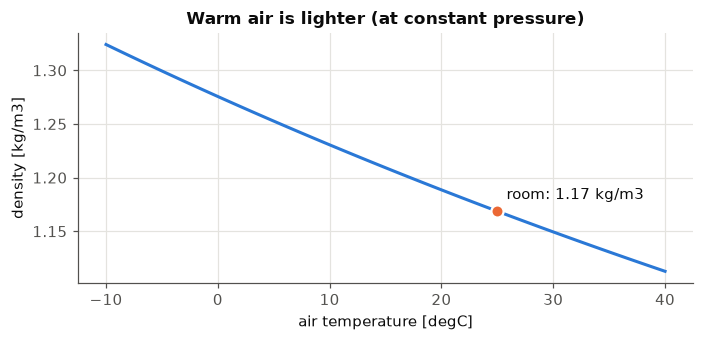

In [2]:
p, R = 1e5, 287                              # Pa, J/(kg.K)
V = 6 * 4 * 3                                # m3
T = 25 + 273.15                              # K
m = p * V / (R * T)                          # kg
rho = m / V                                  # kg/m3
print(f"V = {V} m3   m = {m:.2f} kg   rho = {rho:.2f} kg/m3")   # lecture: 84.14 kg and 84.14/72 = 1.17 kg/m3 (the slide writes 1.16)

t = np.linspace(-10, 40, 100)
fig, ax = plt.subplots(figsize=(6.5, 3.2))
ax.plot(t, p / (R * (t + 273.15)), color=BLUE, lw=2)
ax.plot(25, rho, "o", color=ORANGE, ms=8, mec="white", mew=1.5); ax.annotate(f"room: {rho:.2f} kg/m3", (25, rho), xytext=(6, 8), textcoords="offset points")
ax.set_xlabel("air temperature [degC]"); ax.set_ylabel("density [kg/m3]"); ax.set_title("Warm air is lighter (at constant pressure)")
plt.tight_layout(); plt.show()

**Reading it.** Same pressure, hotter air means the molecules are more spread out, so each m³ weighs less: the density falls from 1.32 kg/m³ at −10 °C to 1.11 kg/m³ at 40 °C. This is why warm air rises. The orange dot is our room: 1.17 kg/m³, which makes about 84 kg of air in the whole 72 m³.

## A2. The data table: how much water can air hold?

The sheet gives measured saturation pressures of water. Between table points we interpolate linearly (a straight line between neighbours). Error is under about 1 %, fine for this lab.

**What "100 % humidity" (saturation) means.** At a given temperature $t$, air can carry water vapour only up to a maximum vapour pressure, the **saturation pressure** $p_{sat}(t)$. The real vapour pressure in the air, $p_v$, is always at or below it. **Relative humidity** says how close the air is to that maximum:

$$\varphi=\frac{p_v}{p_{sat}(t)}$$

- $\varphi$ = 100 % means $p_v=p_{sat}(t)$: the air is **full** (saturated) *at its current temperature*. One more drop of vapour would not stay a gas, it would condense (dew, fog, cloud). "100 % humidity", "100 % relative humidity" and "saturated air" are three names for this one state.
- 100 % does **not** mean "the air is made of water". The air still holds only a few grams of vapour per kg (see $x$ in A3); 100 % just means that, at this temperature, it cannot hold more.
- $\varphi$ = 60 % means the air carries 60 % of its maximum. $\varphi$ = 0 % is perfectly dry air.
- The black curve in the chart below is $p_{sat}(t)$, so **it is the set of all states with $\varphi$ = 100 %**. Every other relative humidity is a curve underneath it ($60\,\% = 0.60\cdot p_{sat}(t)$, the dashed line). A point *on* the curve is full air, a point *below* it can still take water, and a point *above* it cannot exist as vapour.
- The limit moves with temperature, so the same water gives different percentages: the sheet's summer air (30 °C, $p_v$ = 2548 Pa) is only 60 % full, but if it is cooled to 21.4 °C the same 2548 Pa reaches the curve and the air is 100 % full. That temperature is the **dew point** (A4).

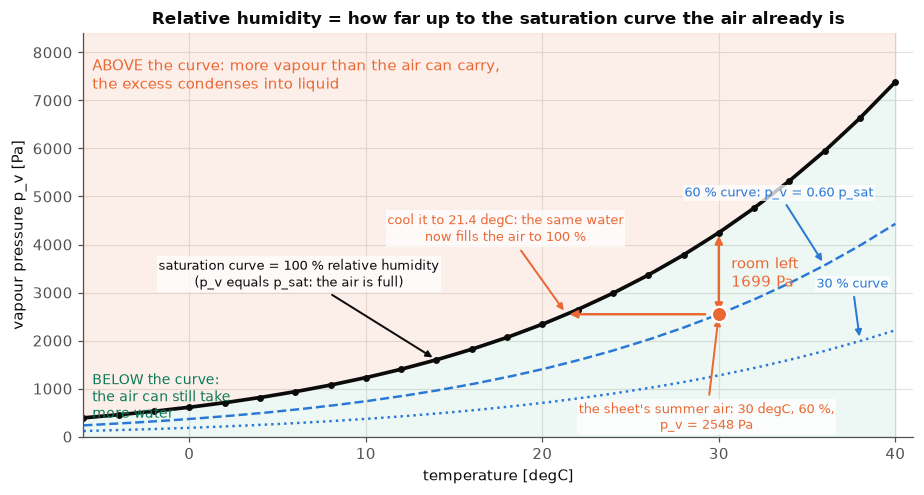

In [3]:
T_TAB = np.arange(-6, 41, 2)
P_TAB = np.array([390.9, 454.9, 527.9, 611.2, 706, 813.5, 935.3, 1073, 1228, 1403, 1599, 1819,
                  2065, 2339, 2645, 2986, 3364, 3783, 4247, 4760, 5325, 5948, 6633, 7385])

def p_sat(t):          # saturation pressure [Pa] by interpolating the sheet's table
    return np.interp(t, T_TAB, P_TAB)

def t_sat(pv):         # inverse: temperature [degC] at which p_sat = pv (this is the dew point)
    return np.interp(pv, P_TAB, T_TAB)

P_ATM = 1e5            # 1 bar [Pa]
def humidity_ratio(pv, p=P_ATM):  return 0.622 * pv / (p - pv)                 # kg water / kg dry air
def enthalpy(t, x):               return t + x * (2500 + 1.84 * t)               # kJ/kg dry air

tt = np.linspace(-6, 40, 200)
t0 = 30; pv0 = 0.60 * float(p_sat(t0)); td0 = float(t_sat(pv0))
fig, ax = plt.subplots(figsize=(8.5, 4.6))
ax.fill_between(tt, p_sat(tt), 8400, color=ORANGE, alpha=0.10)
ax.fill_between(tt, 0, p_sat(tt), color=AQUA, alpha=0.08)
ax.plot(tt, p_sat(tt), color=INK, lw=2.4); ax.plot(T_TAB, P_TAB, "o", color=INK, ms=3.5)
ax.plot(tt, 0.60 * p_sat(tt), color=BLUE, lw=1.6, ls="--"); ax.plot(tt, 0.30 * p_sat(tt), color=BLUE, lw=1.6, ls=":")
ax.text(-5.5, 7900, "ABOVE the curve: more vapour than the air can carry,\nthe excess condenses into liquid", color=ORANGE, va="top")
ax.text(-5.5, 1350, "BELOW the curve:\nthe air can still take\nmore water", color="#0d7a55", va="top", fontsize=9)
point(ax, (14, float(p_sat(14))), "saturation curve = 100 % relative humidity\n(p_v equals p_sat: the air is full)", (-90, 48), color=INK)
point(ax, (36, 0.60 * float(p_sat(36))), "60 % curve: p_v = 0.60 p_sat", (-30, 45), color=BLUE)
point(ax, (38, 0.30 * float(p_sat(38))), "30 % curve", (-5, 35), color=BLUE)
ax.plot(t0, pv0, "o", color=ORANGE, ms=10, mec="white", mew=1.5, zorder=8)
ax.annotate("", (t0, float(p_sat(t0))), (t0, pv0), arrowprops=dict(arrowstyle="<|-|>", color=ORANGE, lw=1.6))
ax.text(t0 + 0.7, (pv0 + p_sat(t0)) / 2, f"room left\n{p_sat(t0) - pv0:.0f} Pa", color=ORANGE, va="center")
ax.annotate("", (td0, pv0), (t0 - 0.6, pv0), arrowprops=dict(arrowstyle="-|>", color=ORANGE, lw=1.6))
point(ax, (t0, pv0), f"the sheet's summer air: {t0} degC, 60 %,\np_v = {pv0:.0f} Pa", (-8, -75), color=ORANGE)
point(ax, (td0, pv0), f"cool it to {td0:.1f} degC: the same water\nnow fills the air to 100 %", (-40, 48), color=ORANGE)
ax.set_xlabel("temperature [degC]"); ax.set_ylabel("vapour pressure p_v [Pa]"); ax.set_ylim(0, 8400); ax.set_xlim(-6, 41)
ax.set_title("Relative humidity = how far up to the saturation curve the air already is")
plt.tight_layout(); plt.show()

**Reading it.** Follow the black curve from left to right: it bends upward, so from 0 °C to 30 °C the capacity grows about **7 times** (611 → 4247 Pa). That is why the same percentage means very different amounts of water on a summer and a winter day (A3). The orange arrow at 30 °C shows how much room the sheet's summer air still has and the horizontal arrow shows how far it must cool to close that gap.

## A3. Solving the sheet: summer day vs winter day

Both days: $p$ = 1 bar. Summer: $t$ = 30 °C, $\varphi$ = 60 %. Winter: $t$ = 0 °C, $\varphi$ = 85 %.

Steps for each day:

1. $p_{sat}(t)$ from the table.
2. $p_v = \varphi\cdot p_{sat}(t)$: the real water pressure.
3. $x = 0.622\,p_v/(p-p_v)$: grams of water per kg of dry air.
4. $t_{dp} = t_{sat}(p_v)$: look the value of $p_v$ up in the table **backwards** to get a temperature.
5. $h = t + x(2500 + 1.84\,t)$: energy per kg of dry air.

In [4]:
cases = {"Summer day": (30, 0.60), "Winter day": (0, 0.85)}
rows = {}
for name, (t, phi) in cases.items():
    ps = p_sat(t); pv = phi * ps; x = humidity_ratio(pv); tdp = t_sat(pv); h = enthalpy(t, x)
    rows[name] = {"t [degC]": t, "phi [%]": phi * 100, "p_sat(t) [Pa]": round(float(ps), 1), "p_v = phi*p_sat [Pa]": round(float(pv), 1),
                  "x [g/kg]": round(1000 * x, 2), "t_dp [degC]": round(float(tdp), 2), "h [kJ/kg]": round(h, 2)}
sheet1 = pd.DataFrame(rows)
sheet1

,Summer day,Winter day
t [degC],30.00,0.00
phi [%],60.00,85.00
p_sat(t) [Pa],4247.00,611.20
p_v = phi*p_sat [Pa],2548.20,519.50
x [g/kg],16.26,3.25
t_dp [degC],21.37,-2.23
h [kJ/kg],71.56,8.12


**Reading the table.**
- **Summer:** the air carries 16.3 g of water per kg of dry air. For comparison, the lecture gives 10 g/kg as the yearly average for Romania, and the comfort standard ASHRAE 55 (American Society of Heating, Refrigerating and Air-Conditioning Engineers, standard 55; used in Part B) caps the humidity ratio at 12 g/kg. Its dew point is 21.4 °C: any surface colder than that (a cold glass, an air-conditioner coil) will drip.
- **Winter:** only 3.2 g/kg. Dew point −2.2 °C: below that, frost or fog forms. Humidity of 85 % *sounds* wet, but cold air holds so little that the absolute amount of water is five times smaller than in summer.
- **Why the percentage misleads:** relative humidity compares $p_v$ with a limit that changes with temperature (A2), so it cannot be compared between a warm and a cold day. $x$ (and $p_v$) tell the real amount: warm air at 60 % holds much more than cold air at 85 %.

## Why do we use vapour *pressure* and not kilograms of water?

**Short answer: we use both, and they are the same information in two forms.** $p_v$ and $x$ are tied together by the ideal gas law, and the sheet uses each where it is the more convenient.

**The link.** Each gas in the mixture follows $pV = mRT$ on its own (Dalton's law). For the vapour and the dry air in the same volume $V$ and at the same temperature $T$:

$$p_v V = m_v R_v T,\qquad p_a V = m_a R_a T \;\;\Longrightarrow\;\; x=\frac{m_v}{m_a}=\frac{R_a}{R_v}\cdot\frac{p_v}{p_a}=0.622\,\frac{p_v}{p-p_v}$$

with $R_a$ = 287 and $R_v$ = 461.5 J/(kg·K), so $R_a/R_v = 0.622$. Also, $p_v = \rho_v R_v T$: **the vapour pressure is just "kilograms of vapour per m³", multiplied by $R_vT$.** Pressure *is* a measure of quantity.

**Why pressure is the natural choice for these jobs:**
1. **Saturation is defined by pressure.** Water vapour can only reach a maximum partial pressure $p_{sat}(t)$ that depends (almost) only on temperature. So "is it full?" is the question $p_v \ge p_{sat}$, and relative humidity is just $\varphi = p_v/p_{sat}$. In kg you would need a different limit for every pressure and temperature.
2. **Dew point** is the temperature where $p_{sat}(t_{dp}) = p_v$, a single table look-up.
3. **Physical measurements** (hygrometers, the evaporation/condensation balance at a surface) respond to the vapour pressure.

**Why we *also* need the kg-based $x$:**
- $x$ is *conserved*: if you heat or cool air and add or remove no water, $x$ does not change. $p_v$ also stays put at constant total pressure, but the vapour **per m³** (and so $\varphi$) changes because the air expands. Mass balances, humidifying and dehumidifying, and enthalpy ($h$ is "per kg of dry air") all need $x$.
- $x$ is **directly** $m_v/m_a$, exactly as you said. The code below shows both routes give the same number.

In [5]:
R_a, R_v = 287.0, 461.5            # gas constants [J/(kg.K)]: dry air, water vapour (R_a/R_v = 0.622)
t, phi = 30, 0.60
T = t + 273.15                     # K
pv = phi * p_sat(t)                # Pa, vapour partial pressure
pa = 1e5 - pv                      # Pa, dry-air partial pressure (Dalton: p = pa + pv)
rho_v = pv / (R_v * T)             # kg of vapour per m3   (from pv = rho_v * R_v * T)
rho_a = pa / (R_a * T)             # kg of dry air per m3  (from pa = rho_a * R_a * T)
print(f"vapour : {rho_v*1000:.2f} g per m3     dry air: {rho_a:.3f} kg per m3")
print(f"x = rho_v/rho_a = {1000*rho_v/rho_a:.2f} g/kg      formula 0.622*pv/(p-pv) = {1000*humidity_ratio(pv):.2f} g/kg   (same thing)")

# heat the SAME air (nothing added, nothing removed, total pressure fixed at 1 bar)
rows = []
for tt_ in (25, 30, 35, 40):
    rows.append({"t [degC]": tt_, "x [g/kg]": round(1000 * humidity_ratio(pv), 2), "p_v [Pa]": round(pv, 1),
                 "vapour [g/m3]": round(1000 * pv / (R_v * (tt_ + 273.15)), 2),
                 "p_sat [Pa]": round(float(p_sat(tt_)), 0), "relative humidity [%]": round(100 * pv / float(p_sat(tt_)))})
pd.DataFrame(rows)

vapour : 18.21 g per m3     dry air: 1.120 kg per m3
x = rho_v/rho_a = 16.26 g/kg      formula 0.622*pv/(p-pv) = 16.26 g/kg   (same thing)


,t [degC],x [g/kg],p_v [Pa],vapour [g/m3],p_sat [Pa],relative humidity [%]
0,25,16.26,2548.2,18.52,3175.0,80
1,30,16.26,2548.2,18.21,4247.0,60
2,35,16.26,2548.2,17.92,5636.0,45
3,40,16.26,2548.2,17.63,7385.0,35


**Reading it.** In the table the humidity ratio $x$ and the vapour pressure $p_v$ **do not change** while we heat the air, since nothing was added or removed. But the vapour per m³ falls (air expands), and the relative humidity falls from 80 % (at 25 °C) to 35 % (at 40 °C), because the "full" limit $p_{sat}$ rises quickly. That is why *relative* humidity is a poor measure of the amount of water, while $x$ (kg/kg) and $p_v$ (Pa) tell the truth.

### Heating the air: where does the extra volume go, and why do $x$ and $t_{dp}$ stay put?

Two statements look contradictory:
1. *Warm air expands, so a cubic metre contains fewer molecules (less vapour, less dry air).*
2. *The humidity ratio $x$ and the dew point $t_{dp}$ do not change when we only heat the air.*

They do not contradict each other, because **$x$ and $t_{dp}$ never measure "how much per m³"**. $x$ compares the vapour with the dry air *that is in the same place*, and $t_{dp}$ is set by $p_v$, the share of the pressure that the vapour provides, which is the vapour's share of the molecules times the total pressure. Heating changes how many molecules fit in a cubic metre, not how they are mixed. What happens to the total pressure then depends on whether the extra volume has somewhere to go.

**A. A real room (it leaks, nothing is airtight).** The heated air tries to expand: at constant pressure $V\propto T$. The part that no longer fits in the room escapes through cracks, windows and ventilation, **taking vapour and dry air out in the same proportion as they were mixed**. The molecules that stay have the same mix, so $x$ is unchanged. The pressure stays at the outside value (1 bar), so $p_v=(\text{vapour share})\cdot p$ is unchanged and the dew point is unchanged. Per m³ there is less of both (the grey and blue dots in the figure inside the room are fewer), and the relative humidity falls because $p_{sat}$ grew (A2). The air did not go "somewhere else" in the sense of losing its water content: it just left with its own share of water.

**B. An isolated (sealed, rigid) room.** Nothing can leave and the volume cannot grow, so the same molecules now move faster and hit the walls harder. Pressure rises, and not magically: it is the ideal gas law $p=\rho R T$ with $\rho$ fixed, so $p\propto T$. From 30 °C to 40 °C that is a factor $313.15/303.15=1.033$, so 1 bar becomes about 1.033 bar (3.3 kPa more: this is why sealed cans and bottles burst when heated). Each gas's partial pressure rises by the same factor, so $p_v$ rises from 2548 to 2632 Pa. Since the masses of vapour and dry air did not change, **$x$ is exactly unchanged**, but because $p_v$ rose the **dew point rises slightly, from 21.4 °C to 21.9 °C**. So your intuition about a pressure increase is right for a sealed room, but the effect on the dew point is small (+0.55 °C), and it comes from the pressure increase, not from the expansion.

The first figure draws the three situations (the number of dots and the expansion are exaggerated so that you can see them). The second figure compares the quantities for a room started at 30 °C and 60 %.

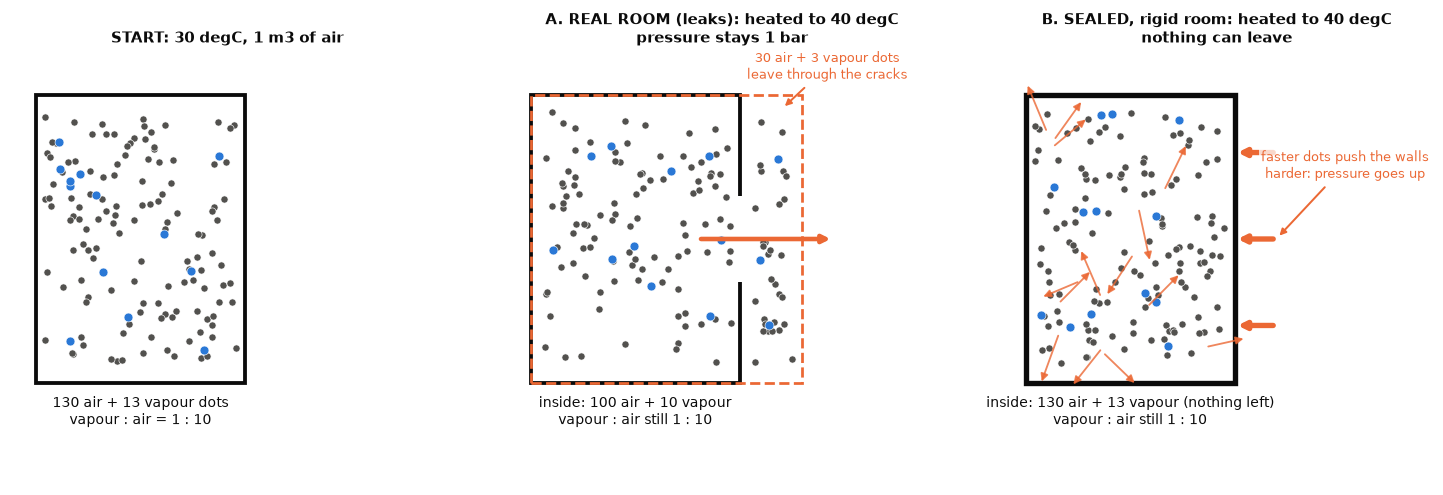

In [6]:
# schematic of one room (30 degC -> 40 degC). Numbers of dots are exaggerated for visibility: vapour = blue, dry air = grey
rng = np.random.default_rng(7)
N_AIR, N_VAP, GROW = 130, 13, 1.30            # a real 30 -> 40 degC step only expands the air by 3.3 %; drawn as 30 % so it is visible
def scatter_in(ax, n, x0, x1, color, size=22):
    ax.scatter(rng.uniform(x0 + 0.04, x1 - 0.04, n), rng.uniform(0.06, 0.94, n), s=size, color=color, edgecolor="white", lw=0.4, zorder=3)
def room(ax, w=1.0, ls="-", color=INK, lw=2.5):
    ax.add_patch(plt.Rectangle((0, 0), w, 1, fill=False, ec=color, lw=lw, ls=ls, zorder=2))
def speed(ax, n, length, color):
    px, py = rng.uniform(0.1, 0.9, n), rng.uniform(0.1, 0.9, n); ang = rng.uniform(0, 2 * np.pi, n)
    for a, b, t in zip(px, py, ang):
        ax.annotate("", (a + length * np.cos(t), b + length * np.sin(t)), (a, b), arrowprops=dict(arrowstyle="-|>", color=color, lw=1.2, alpha=0.8), zorder=4)

fig, axs = plt.subplots(1, 3, figsize=(13.5, 4.6))
for ax in axs: ax.set_xlim(-0.12, 1.95); ax.set_ylim(-0.35, 1.15); ax.axis("off")

ax = axs[0]; room(ax); scatter_in(ax, N_AIR, 0, 1, MUTED); scatter_in(ax, N_VAP, 0, 1, BLUE, 34)
ax.set_title("START: 30 degC, 1 m3 of air", fontsize=10)
ax.text(0.5, -0.04, f"{N_AIR} air + {N_VAP} vapour dots\nvapour : air = 1 : 10", ha="center", va="top", fontsize=9)

ax = axs[1]; room(ax); room(ax, GROW, ls="--", color=ORANGE, lw=1.8)            # dashed = where the heated air would like to be
keep = int(N_AIR / GROW); keepv = int(round(N_VAP / GROW))
scatter_in(ax, keep, 0, 1, MUTED); scatter_in(ax, keepv, 0, 1, BLUE, 34)
scatter_in(ax, N_AIR - keep, 1.02, GROW, MUTED); scatter_in(ax, N_VAP - keepv, 1.02, GROW, BLUE, 34)
ax.add_patch(plt.Rectangle((0.985, 0.35), 0.05, 0.3, fc="white", ec="none", zorder=5)); ax.annotate("", (1.45, 0.5), (0.8, 0.5), arrowprops=dict(arrowstyle="-|>", color=ORANGE, lw=3), zorder=6)
point(ax, (1.2, 0.95), f"{N_AIR - keep} air + {N_VAP - keepv} vapour dots\nleave through the cracks", (30, 20), color=ORANGE)
ax.set_title("A. REAL ROOM (leaks): heated to 40 degC\npressure stays 1 bar", fontsize=10)
ax.text(0.5, -0.04, f"inside: {keep} air + {keepv} vapour\nvapour : air still 1 : 10", ha="center", va="top", fontsize=9)

ax = axs[2]; room(ax, lw=3.5, color=INK); scatter_in(ax, N_AIR, 0, 1, MUTED); scatter_in(ax, N_VAP, 0, 1, BLUE, 34)
speed(ax, 14, 0.2, ORANGE)
for yy in (0.2, 0.5, 0.8):
    ax.annotate("", (1.0, yy), (1.2, yy), arrowprops=dict(arrowstyle="-|>", color=ORANGE, lw=3.5));
point(ax, (1.2, 0.5), "faster dots push the walls\nharder: pressure goes up", (45, 40), color=ORANGE)
ax.set_title("B. SEALED, rigid room: heated to 40 degC\nnothing can leave", fontsize=10)
ax.text(0.5, -0.04, f"inside: {N_AIR} air + {N_VAP} vapour (nothing left)\nvapour : air still 1 : 10", ha="center", va="top", fontsize=9)
plt.tight_layout(); plt.show()

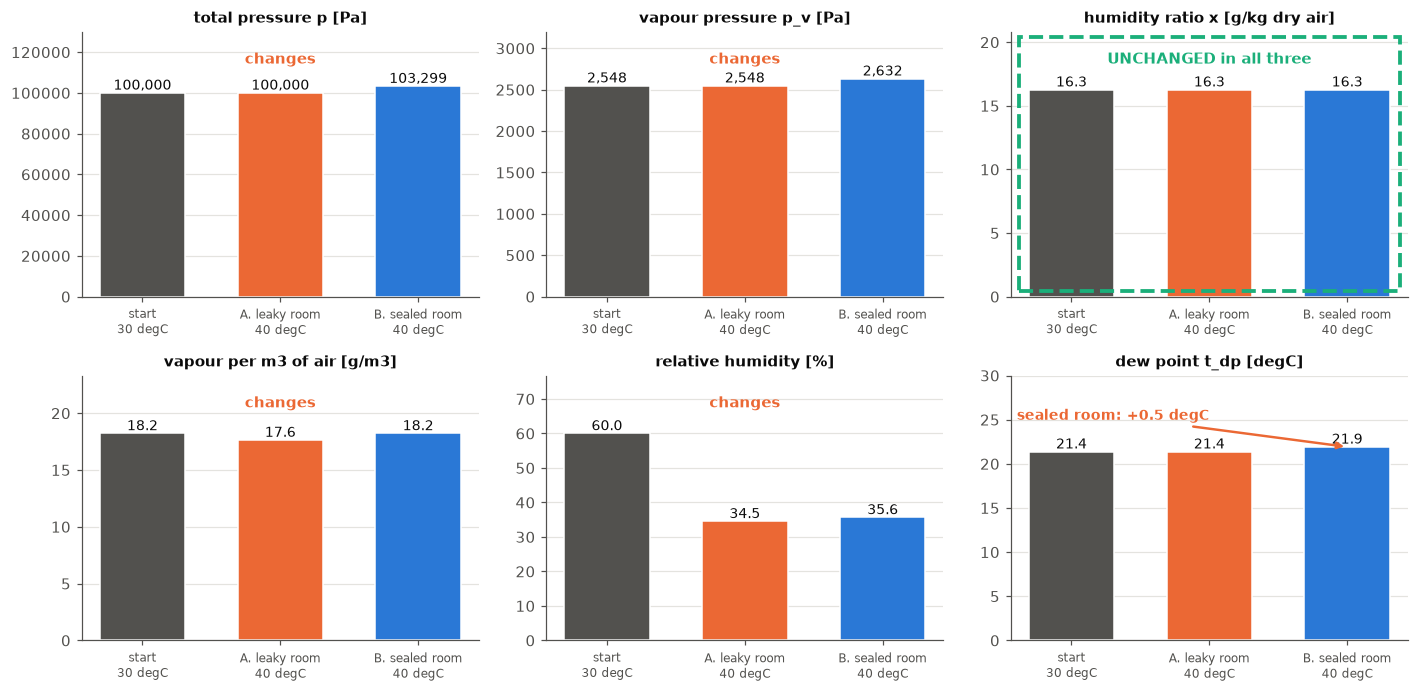

                                 start 30 degC  A. leaky room 40 degC  B. sealed room 40 degC
total pressure p [Pa]                100000.00              100000.00               103298.70
vapour pressure p_v [Pa]               2548.20                2548.20                 2632.26
humidity ratio x [g/kg dry air]          16.26                  16.26                   16.26
vapour per m3 of air [g/m3]              18.21                  17.63                   18.21
relative humidity [%]                    60.00                  34.51                   35.64
dew point t_dp [degC]                    21.37                  21.37                   21.92


In [7]:
# the same story in numbers: start 30 degC / 60 % / 1 bar, then heated to 40 degC
R_v = 461.5
t_start, t_end2 = 30.0, 40.0; k_ratio = (t_end2 + 273.15) / (t_start + 273.15)
pv_start = 0.60 * float(p_sat(t_start)); p_start = 1e5
cases3 = {"start\n30 degC": (pv_start, p_start, t_start), "A. leaky room\n40 degC": (pv_start, p_start, t_end2), "B. sealed room\n40 degC": (pv_start * k_ratio, p_start * k_ratio, t_end2)}
rows3 = {"total pressure p [Pa]": [], "vapour pressure p_v [Pa]": [], "humidity ratio x [g/kg dry air]": [], "vapour per m3 of air [g/m3]": [],
        "relative humidity [%]": [], "dew point t_dp [degC]": []}
for pv, p, t in cases3.values():
    rows3["total pressure p [Pa]"].append(p); rows3["vapour pressure p_v [Pa]"].append(pv); rows3["humidity ratio x [g/kg dry air]"].append(1000 * humidity_ratio(pv, p))
    rows3["vapour per m3 of air [g/m3]"].append(1000 * pv / (R_v * (t + 273.15)) if p == p_start else 1000 * pv_start / (R_v * (t_start + 273.15)))   # sealed: same mass in the same m3
    rows3["relative humidity [%]"].append(100 * pv / float(p_sat(t))); rows3["dew point t_dp [degC]"].append(float(t_sat(pv)))
labels3 = list(cases3); cols3 = [MUTED, ORANGE, BLUE]
fig, axs = plt.subplots(2, 3, figsize=(13, 6.4))
for ax, (title, vals) in zip(axs.ravel(), rows3.items()):
    b = ax.bar(range(3), vals, color=cols3, edgecolor="white", width=0.62)
    lo, hi = min(vals), max(vals); same = (hi - lo) / hi < 1e-3
    for i, v in enumerate(vals): ax.text(i, v, f"{v:.1f}" if v < 1000 else f"{v:,.0f}", ha="center", va="bottom", fontsize=9)
    ax.set_xticks(range(3)); ax.set_xticklabels(labels3, fontsize=8); ax.set_title(title, fontsize=10)
    ax.set_ylim(0, hi * 1.28); ax.grid(axis="x", visible=False)
    if same:
        ax.text(0.5, 0.88, "UNCHANGED in all three", transform=ax.transAxes, ha="center", color=AQUA, fontweight="bold", fontsize=10)
        ax.add_patch(plt.Rectangle((0.02, 0.02), 0.96, 0.96, transform=ax.transAxes, fill=False, ec=AQUA, lw=2.5, ls="--"))
    elif title.startswith("dew point"):
        ax.annotate(f"sealed room: +{vals[2] - vals[0]:.1f} degC", (2, vals[2]), xytext=(0.3, hi * 1.14), arrowprops=dict(arrowstyle="-|>", color=ORANGE, lw=1.6), color=ORANGE, fontweight="bold", fontsize=9, ha="center")
    else:
        ax.text(0.5, 0.88, "changes", transform=ax.transAxes, ha="center", color=ORANGE, fontweight="bold", fontsize=10)
axs[0, 0].set_ylim(0, 1.3e5); axs[0, 1].set_ylim(0, 3200); axs[1, 2].set_ylim(0, 30)
plt.tight_layout(); plt.show()
print(pd.DataFrame(rows3, index=[n.replace("\n", " ") for n in labels3]).T.round(2).to_string())

## A4. Dew point on the saturation curve

Start at the air's state: its temperature and its $p_v$. Cool it **without adding or removing water**. Then $p_v$ does not change, so the state moves along a **horizontal line to the left**, while the temperature falls and the curve $p_{sat}(t)$ above it comes down to meet it. The meeting point is where the air reaches 100 % relative humidity (the saturation curve of A2): the **dew point**. Each day's own relative humidity ($60\,\%$ in summer, $85\,\%$ in winter) is the dashed curve through its starting point.

**The dew point as a function.** The dew point is the temperature at which the saturation pressure equals the air's vapour pressure:

$$p_{sat}(t_{dp}) = p_v \quad\Longrightarrow\quad t_{dp}=p_{sat}^{-1}(p_v)$$

So it is the **inverse of the saturation curve**: you enter with $p_v$ and read off a temperature. Sheet 1 does this by reading the table backwards (interpolating between rows). Sheet 2 gives the curve as the Antoine equation, $p_{sat}(t)=e^{16.6536-4030.183/(t+235)}$ in kPa, and solving it for $t$ gives a closed formula:

$$t_{dp}=\frac{4030.183}{16.6536-\ln p_v}-235\qquad(p_v\text{ in kPa})$$

If only the air temperature $t$ and the relative humidity $\varphi$ are known, first get $p_v=\varphi\cdot p_{sat}(t)$ and then apply the formula.

**Why the dew point does not depend on the air temperature.** "Saturation pressure" means two different things here:
- the **curve** $p_{sat}(\cdot)$, a fixed property of water, the same for any air;
- the **value** $p_{sat}(t)$ at the air's current temperature, one point of that curve, which is the air's current ceiling.

The dew point uses the curve, read backwards from $p_v$, and never the air temperature $t$. When the air is heated and no water is added, the ceiling $p_{sat}(t)$ rises and the relative humidity falls, but $p_v$ and the curve are unchanged, so $t_{dp}$ is unchanged. The dew point moves only when $p_v$ moves: evaporation raises both, condensation lowers both, and in a sealed room heating raises $p_v$ slightly (see the section on heating the air above). Because $p_{sat}$ always increases with temperature, a higher dew point always means more water in the air.

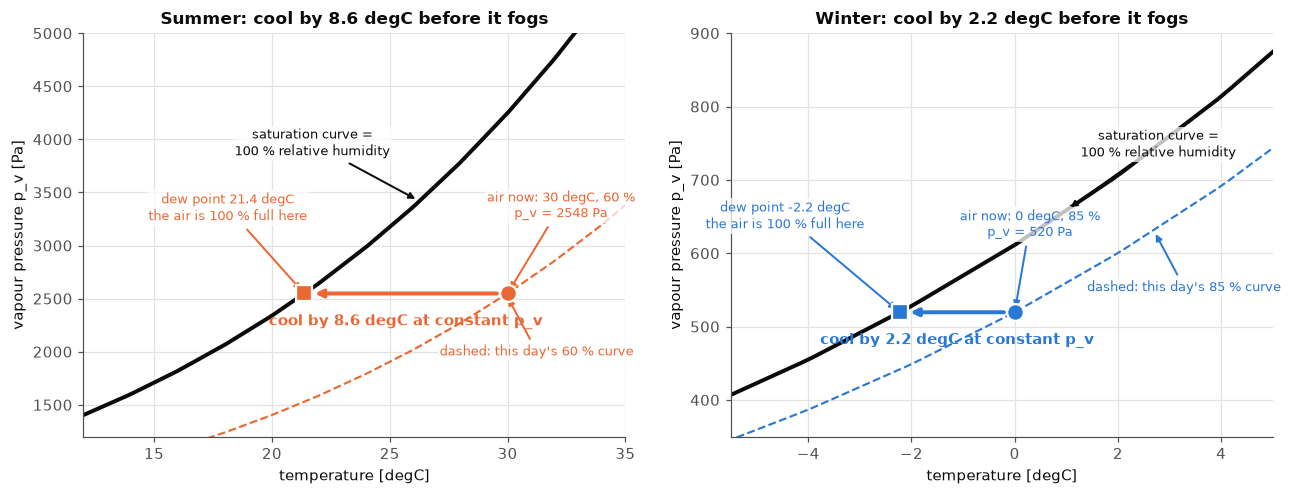

In [8]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4.6))
zoom = {"Summer": ((12, 35), (1200, 5000), (-50, 48), (-70, 30)), "Winter": ((-5.5, 5), (350, 900), (-75, 55), (60, 35))}
for ax, (name, (t, phi)), col in zip(axs, (("Summer", cases["Summer day"]), ("Winter", cases["Winter day"])), (SUMMER, WINTER)):
    (x0, x1), (y0, y1), off_dp, off_curve = zoom[name]
    pv = phi * p_sat(t); tdp = float(t_sat(pv))
    ax.plot(tt, p_sat(tt), color=INK, lw=2.6)
    ax.plot(tt, phi * p_sat(tt), color=col, lw=1.4, ls="--")                                     # curve of constant relative humidity
    ax.annotate("", (tdp, pv), (t, pv), arrowprops=dict(arrowstyle="-|>", color=col, lw=2.6, shrinkA=7, shrinkB=7))   # cooling at constant p_v
    ax.plot(t, pv, "o", color=col, ms=11, mec="white", mew=1.5, zorder=8)                        # current state
    ax.plot(tdp, pv, "s", color=col, ms=10, mec="white", mew=1.5, zorder=8)                      # dew point, on the 100 % curve
    ax.text((t + tdp) / 2, pv - 0.05 * (y1 - y0), f"cool by {t - tdp:.1f} degC at constant p_v", ha="center", va="top", color=col, fontweight="bold")
    point(ax, (t, pv), f"air now: {t} degC, {phi*100:.0f} %\np_v = {pv:.0f} Pa", (35 if name == "Summer" else 10, 50), color=col)
    point(ax, (tdp, pv), f"dew point {tdp:.1f} degC\nthe air is 100 % full here", off_dp, color=col)
    xc = x0 + 0.62 * (x1 - x0)
    point(ax, (xc, float(p_sat(xc))), "saturation curve =\n100 % relative humidity", off_curve, color=INK)
    xd = x0 + 0.78 * (x1 - x0)
    point(ax, (xd, phi * float(p_sat(xd))), f"dashed: this day's {phi*100:.0f} % curve", (20, -40), color=col)
    ax.set_xlim(x0, x1); ax.set_ylim(y0, y1); ax.set_xlabel("temperature [degC]"); ax.set_ylabel("vapour pressure p_v [Pa]")
    ax.set_title(f"{name}: cool by {t - tdp:.1f} degC before it fogs")
plt.tight_layout(); plt.show()

**Reading it.** Circle = the air now. Square = its dew point, always **on the black 100 % curve**. The arrow is the cooling path, a constant-$p_v$ line. Summer air only has to cool by about 8.6 °C before it reaches 100 % and fogs; winter air by about 2.2 °C, even though its relative humidity (85 %) looks closer to full than the summer's 60 %: the arrow is short because both the starting point and the curve are low (small $p_{sat}$).

## Condensation: what it is and when it happens

**Condensation** is water vapour turning into **liquid** water (the reverse of evaporation). It is what makes dew, fog, clouds, the mist on a bathroom mirror and the drops on a cold glass.

**When:** the air can only carry vapour up to $p_{sat}(t)$. If the air is cooled (or a cold surface touches it) so that $p_v$ would exceed $p_{sat}$, the excess cannot stay a gas and **becomes liquid**. The temperature at which this starts is exactly the **dew point** $t_{dp}$. So:

- surface warmer than $t_{dp}$ → stays dry;
- surface colder than $t_{dp}$ → the air next to it condenses on it.

**Energy:** condensing **releases** the latent heat that evaporation absorbed, about 2500 kJ per kg of water. An air-conditioner coil therefore does two jobs, cooling the air *and* making it condense (drying it), and the second one costs a lot of energy.

**Why buildings care:** a winter window or a cold wall corner below the room's dew point collects water, which leads to mould, damaged finishes and (when below 0 °C) frost.

**Two humidity ratios appear in the chart below, and they are different quantities.**
- **Actual humidity ratio $x$**: the water the air really carries. If no water is added or removed, it **does not change with temperature**, so on the chart it is a flat line.
- **Saturation humidity ratio $x_{sat}(t)$**: the humidity ratio the air would have if it were 100 % full at temperature $t$. It is the same formula as $x$ with $p_{sat}(t)$ in place of $p_v$:

$$x_{sat}(t)=0.622\,\frac{p_{sat}(t)}{p-p_{sat}(t)}$$

It depends only on the temperature. It is the saturation pressure curve of A2 rewritten in g/kg: the **ceiling** for each temperature, not the amount of water that is there.

Cooling moves the air to the left along the flat line (nothing is removed, so $x$ is constant) until the line meets the ceiling: the dew point. Cooling further, the ceiling would drop below $x$, which is impossible, so the excess condenses and $x$ falls, following the curve. **$x$ changes with temperature only after condensation has started.**

At 15 degC the air can hold only 10.81 g/kg, it carries 16.26 g/kg
-> 5.45 g of every kg turns to liquid; for the room's 84.14 kg of air that is 459 g of water
-> condensing releases 13.6 kJ per kg of air, 1146 kJ in the room


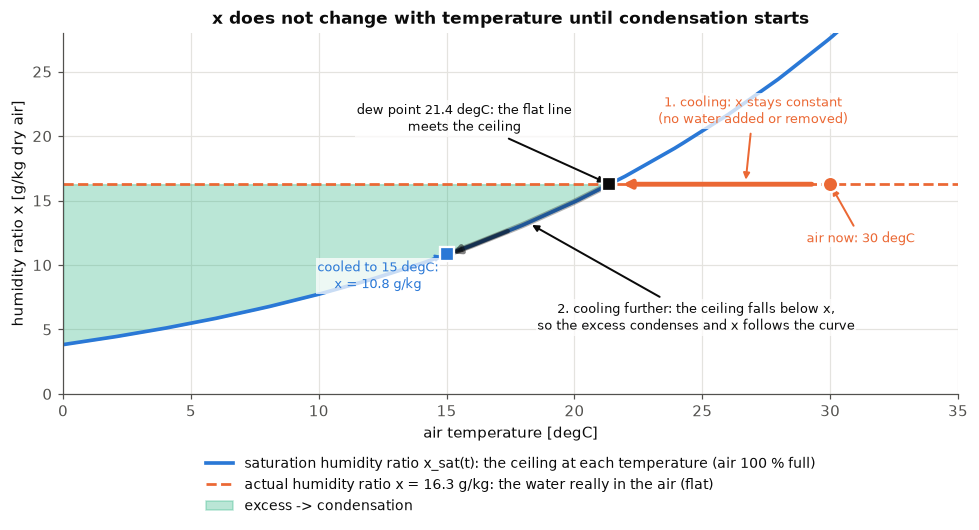

In [9]:
t0, phi0, t_end = 30, 0.60, 15
x_now = 1000 * humidity_ratio(phi0 * p_sat(t0))          # g/kg, what the air carries
x_end = 1000 * humidity_ratio(p_sat(t_end))              # g/kg, the most air at 15 degC can carry
drop = x_now - x_end                                     # g of liquid per kg of dry air
room_air = 84.14                                         # kg, the air mass of the 6x4x3 m room (A1)
print(f"At {t_end} degC the air can hold only {x_end:.2f} g/kg, it carries {x_now:.2f} g/kg")
print(f"-> {drop:.2f} g of every kg turns to liquid; for the room's {room_air} kg of air that is {drop*room_air:.0f} g of water")
print(f"-> condensing releases {drop/1000*2500:.1f} kJ per kg of air, {drop/1000*2500*room_air:.0f} kJ in the room")

tt2 = np.linspace(0, 35, 200)
x_sat = 1000 * humidity_ratio(p_sat(tt2))
td = float(t_sat(phi0 * p_sat(t0)))                      # dew point: where the flat line meets the curve
xs = lambda t: 1000 * humidity_ratio(p_sat(t))
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(tt2, x_sat, color=BLUE, lw=2.4, label="saturation humidity ratio x_sat(t): the ceiling at each temperature (air 100 % full)")
ax.axhline(x_now, color=ORANGE, ls="--", lw=1.8, label=f"actual humidity ratio x = {x_now:.1f} g/kg: the water really in the air (flat)")
ax.fill_between(tt2, x_sat, x_now, where=x_sat < x_now, color=AQUA, alpha=0.3, label="excess -> condensation")
ax.annotate("", (td + 0.4, x_now), (t0 - 0.6, x_now), arrowprops=dict(arrowstyle="-|>", color=ORANGE, lw=3.2))          # stage 1: x constant
tc = np.linspace(td, t_end, 40); ax.plot(tc, xs(tc), color=INK, lw=4, alpha=0.3)                                         # stage 2: follows the curve
ax.annotate("", (t_end + 0.1, xs(t_end)), (t_end + 2.5, xs(t_end + 2.5)), arrowprops=dict(arrowstyle="-|>", color=INK, lw=3, alpha=0.5))
ax.plot(t0, x_now, "o", color=ORANGE, ms=10, mec="white", mew=1.5, zorder=8); ax.plot(td, x_now, "s", color=INK, ms=9, mec="white", mew=1.5, zorder=8)
ax.plot(t_end, x_end, "s", color=BLUE, ms=9, mec="white", mew=1.5, zorder=8)
point(ax, (t0, x_now), f"air now: {t0} degC", (20, -38), color=ORANGE)
point(ax, ((t0 + td) / 2 + 1, x_now), "1. cooling: x stays constant\n(no water added or removed)", (5, 40), color=ORANGE)
point(ax, (td, x_now), f"dew point {td:.1f} degC: the flat line\nmeets the ceiling", (-95, 35), color=INK)
point(ax, ((td + t_end) / 2, xs((td + t_end) / 2)), "2. cooling further: the ceiling falls below x,\nso the excess condenses and x follows the curve", (110, -70), color=INK)
point(ax, (t_end, x_end), f"cooled to {t_end} degC:\nx = {x_end:.1f} g/kg", (-45, -22), color=BLUE)
ax.set_xlabel("air temperature [degC]"); ax.set_ylabel("humidity ratio x [g/kg dry air]"); ax.set_ylim(0, 28); ax.set_xlim(0, 35)
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.14), fontsize=9)
ax.set_title("x does not change with temperature until condensation starts")
plt.tight_layout(); plt.show()

**Reading it.** Summer air (30 °C, 60 %) has a dew point of 21.4 °C. Cooled to 15 °C it can hold only about 10.8 g/kg instead of 16.3, so about 5.5 g per kg of air turns to liquid. For the 84 kg of air in our room that is roughly **0.46 litres of water** and about **1.1 MJ** of latent heat released. In the chart, the green area is the "too much" water that has to leave the air. The flat orange line is the water the air really carries (constant while cooling), the blue curve is the ceiling $x_{sat}(t)$, and the two arrows mark the two stages: along the flat line down to the dew point, then along the curve while the excess condenses.

## Specific heat: how much energy does it take to warm something?

**Definition.** The **specific heat** $c$ of a substance is the energy needed to raise **1 kg** of it by **1 K** (1 °C):

$$Q = m\,c\,\Delta T\qquad[\mathrm{kJ}] = [\mathrm{kg}]\cdot[\mathrm{kJ/(kg\cdot K)}]\cdot[\mathrm{K}]$$

"Specific" means "per kg". A large $c$ means the material is hard to warm up and stores a lot of heat (water); a small $c$ means it warms quickly (air). For gases it depends on whether the pressure is held fixed ($c_p$, used for open air at constant pressure) or the volume ($c_v$). We use $c_p$.

| Substance | $c_p$ [kJ/(kg·K)] |
|---|---|
| Dry air | **1.006** (the sheet rounds it to 1, which changes $h$ by only 0.25 %) |
| Water vapour | **1.84** |
| Liquid water | **4.19** |

**Where it appears in the sheet.** The enthalpy formula is just specific heats applied to the two ingredients:

$$h = \underbrace{c_{pa}\,t}_{\text{dry air: }1\cdot t} + x\,\big(\underbrace{2500}_{\text{evaporation}} + \underbrace{1.84\,t}_{c_{pv}\,t}\big)$$

The 1 in front of $t$ is the specific heat of dry air, and the 1.84 is the specific heat of water vapour. The 2500 kJ/kg is *not* a specific heat: it is the **latent heat of vaporisation**, the energy to turn 1 kg of liquid into vapour at 0 °C with no temperature change.

In [10]:
c_pa, c_pv, c_w = 1.006, 1.84, 4.19                  # specific heats [kJ/(kg.K)]: dry air, vapour, liquid water
m_room = 84.14                                       # kg of air in the 6x4x3 m room
print(f"warm the room's air by 1 K : {m_room*c_pa:6.1f} kJ")
print(f"warm the same MASS of water: {m_room*c_w:6.1f} kJ   ({c_w/c_pa:.1f} times more)")

x = humidity_ratio(0.60 * p_sat(30)); t = 30          # summer day
air_part = t                                          # sheet: c_pa taken as 1 -> 1*t
vap_part = x * 1.84 * t                               # sensible heat of the vapour
latent = x * 2500                                     # evaporation energy
print(f"h = {air_part:.2f} (dry air) + {vap_part:.2f} (vapour warmth) + {latent:.2f} (latent) = {air_part+vap_part+latent:.2f} kJ/kg")
print(f"with c_pa = 1.006 instead of 1: h = {c_pa*t+vap_part+latent:.2f} kJ/kg (difference {100*(c_pa-1)*t/(air_part+vap_part+latent):.2f} %)")

warm the room's air by 1 K :   84.6 kJ
warm the same MASS of water:  352.5 kJ   (4.2 times more)
h = 30.00 (dry air) + 0.90 (vapour warmth) + 40.66 (latent) = 71.56 kJ/kg
with c_pa = 1.006 instead of 1: h = 71.74 kJ/kg (difference 0.25 %)


**Reading it.** To warm the room's air by 1 °C takes about 85 kJ, but the same mass of water would need over 350 kJ: water stores about 4 times more heat per kg than air. In the enthalpy of the summer air, 30 kJ/kg is the dry air's warmth, 0.9 is the vapour's warmth and 40.7 is the latent energy.

## A5. Enthalpy: where is the energy hiding?

$h = \underbrace{t}_{\text{sensible}} + \underbrace{x(2500+1.84\,t)}_{\text{latent}}$

- **Sensible** heat is the warmth you can feel and measure with a thermometer.
- **Latent** heat is energy stored in the water vapour (what it took to evaporate it). You do not feel it directly, but an air conditioner must remove it to dry the air.

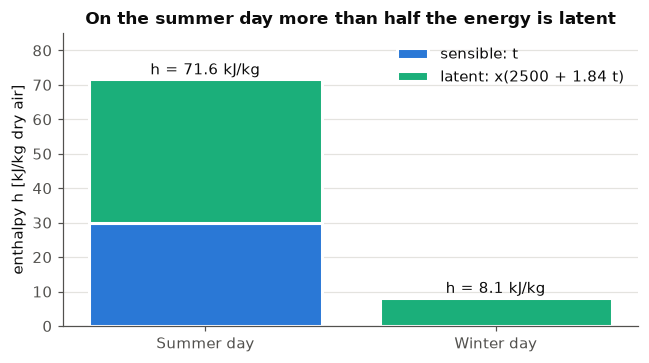

In [11]:
names = list(cases); sens, lat = [], []
for n in names:
    t, phi = cases[n]; x = humidity_ratio(phi * p_sat(t))
    sens.append(t); lat.append(x * (2500 + 1.84 * t))
fig, ax = plt.subplots(figsize=(6, 3.4))
ax.bar(names, sens, color=BLUE, edgecolor="white", linewidth=2, label="sensible: t")
ax.bar(names, lat, bottom=sens, color=AQUA, edgecolor="white", linewidth=2, label="latent: x(2500 + 1.84 t)")
for i in range(2):
    ax.text(i, sens[i] + lat[i] + 1.5, f"h = {sens[i] + lat[i]:.1f} kJ/kg", ha="center")
ax.set_ylabel("enthalpy h [kJ/kg dry air]"); ax.set_ylim(0, 85); ax.legend(frameon=False, loc="upper right"); ax.grid(axis="x", visible=False)
ax.set_title("On the summer day more than half the energy is latent")
plt.tight_layout(); plt.show()

**Reading it.** In summer, about 42 of the 71.6 kJ/kg are latent, hidden in the humidity. Cooling this air to a comfortable temperature is only half the job: the air also has to be dried. In winter, the latent part (8.1) is the whole enthalpy, because 0 °C contributes no sensible energy.

## A6. Individual work: the whole day (Bucharest, Meteonorm data)

The sheet gives **24 hourly values** of $t$ and $\varphi$ for **August 8th** and **February 1st** (UTC = Coordinated Universal Time, the world reference clock; Romanian local time is UTC+3 in summer, UTC+2 in winter). We apply the same five steps to every hour.

In [12]:
hours = np.arange(1, 25)
t_s = np.array([22.5, 21.8, 21, 21, 20.7, 20.9, 22, 23.3, 24.4, 25.6, 26.3, 26.9, 27.3, 27.7, 27.9, 27.9, 27.3, 26.7, 25.9, 24.6, 23.3, 22, 20.6, 19.3])
f_s = np.array([83, 89, 90, 91, 89, 86, 80, 80, 62, 55, 54, 53, 48, 47, 46, 44, 56, 46, 49, 53, 53, 55, 59, 60])
t_w = np.array([3.5, 2.9, 2.2, 1.9, 1.6, 1.3, 1.1, 1.4, 3.3, 5.3, 6.7, 7.4, 7.9, 7.9, 7.7, 7, 5.8, 5.3, 4.8, 4.3, 3.8, 3.3, 2.8, 2.3])
f_w = np.array([79, 81, 84, 81, 83, 83, 85, 84, 77, 72, 73, 74, 69, 66, 67, 74, 78, 77, 77, 81, 82, 87, 86, 85])

def day_table(t, phi):
    pv = phi / 100 * p_sat(t); x = humidity_ratio(pv)
    return pd.DataFrame({"hour (UTC)": hours, "t": t, "phi": phi, "p_v [Pa]": pv.round(0), "x [g/kg]": (1000 * x).round(2),
                         "t_dp": t_sat(pv).round(1), "h [kJ/kg]": enthalpy(t, x).round(1)})
summer_day, winter_day = day_table(t_s, f_s), day_table(t_w, f_w)
print("SUMMER, 8 August");  display(summer_day.set_index("hour (UTC)").T.iloc[:, :12]); display(summer_day.set_index("hour (UTC)").T.iloc[:, 12:])
print("WINTER, 1 February"); display(winter_day.set_index("hour (UTC)").T.iloc[:, :12]); display(winter_day.set_index("hour (UTC)").T.iloc[:, 12:])

SUMMER, 8 August


hour (UTC),1,2,3,4,5,6,7,8,9,10,11,12
t,22.50,21.80,21.00,21.00,20.70,20.90,22.00,23.3,24.40,25.60,26.30,26.90
phi,83.00,89.00,90.00,91.00,89.00,86.00,80.00,80.0,62.00,55.00,54.00,53.00
p_v [Pa],2266.00,2327.00,2243.00,2268.00,2177.00,2130.00,2116.00,2293.0,1898.00,1809.00,1850.00,1883.00
x [g/kg],14.42,14.82,14.27,14.43,13.84,13.54,13.45,14.6,12.04,11.46,11.73,11.94
t_dp,19.50,19.90,19.30,19.50,18.80,18.50,18.40,19.7,16.60,15.90,16.30,16.50
h [kJ/kg],59.20,59.40,57.20,57.60,55.80,55.30,56.20,60.4,55.00,54.80,56.20,57.30


hour (UTC),13,14,15,16,17,18,19,20,21,22,23,24
t,27.30,27.70,27.90,27.90,27.30,26.70,25.90,24.60,23.3,22.00,20.60,19.30
phi,48.00,47.00,46.00,44.00,56.00,46.00,49.00,53.00,53.0,55.00,59.00,60.00
p_v [Pa],1745.00,1748.00,1731.00,1655.00,2036.00,1615.00,1639.00,1643.00,1519.0,1455.00,1434.00,1346.00
x [g/kg],11.05,11.07,10.95,10.47,12.93,10.21,10.37,10.39,9.6,9.18,9.05,8.49
t_dp,15.30,15.40,15.20,14.50,17.80,14.10,14.40,14.40,13.2,12.50,12.30,11.30
h [kJ/kg],55.50,55.90,55.80,54.60,60.30,52.70,52.30,51.00,47.7,45.30,43.60,40.80


WINTER, 1 February


hour (UTC),1,2,3,4,5,6,7,8,9,10,11,12
t,3.50,2.90,2.20,1.90,1.60,1.30,1.10,1.40,3.30,5.30,6.7,7.40
phi,79.00,81.00,84.00,81.00,83.00,83.00,85.00,84.00,77.00,72.00,73.0,74.00
p_v [Pa],621.00,611.00,602.00,568.00,570.00,558.00,564.00,569.00,597.00,643.00,718.0,763.00
x [g/kg],3.89,3.82,3.77,3.55,3.57,3.49,3.53,3.56,3.74,4.02,4.5,4.79
t_dp,0.20,-0.00,-0.20,-1.00,-1.00,-1.30,-1.10,-1.00,-0.30,0.70,2.2,3.10
h [kJ/kg],13.20,12.50,11.60,10.80,10.50,10.00,9.90,10.30,12.70,15.40,18.0,19.40


hour (UTC),13,14,15,16,17,18,19,20,21,22,23,24
t,7.90,7.90,7.70,7.00,5.80,5.3,4.80,4.30,3.80,3.30,2.80,2.30
phi,69.00,66.00,67.00,74.00,78.00,77.0,77.00,81.00,82.00,87.00,86.00,85.00
p_v [Pa],736.00,704.00,705.00,743.00,720.00,687.0,664.00,674.00,658.00,675.00,644.00,614.00
x [g/kg],4.61,4.41,4.42,4.66,4.51,4.3,4.16,4.22,4.12,4.23,4.03,3.84
t_dp,2.60,2.00,2.00,2.70,2.30,1.6,1.10,1.30,1.00,1.30,0.70,0.10
h [kJ/kg],19.50,19.00,18.80,18.70,17.10,16.1,15.20,14.90,14.10,13.90,12.90,11.90


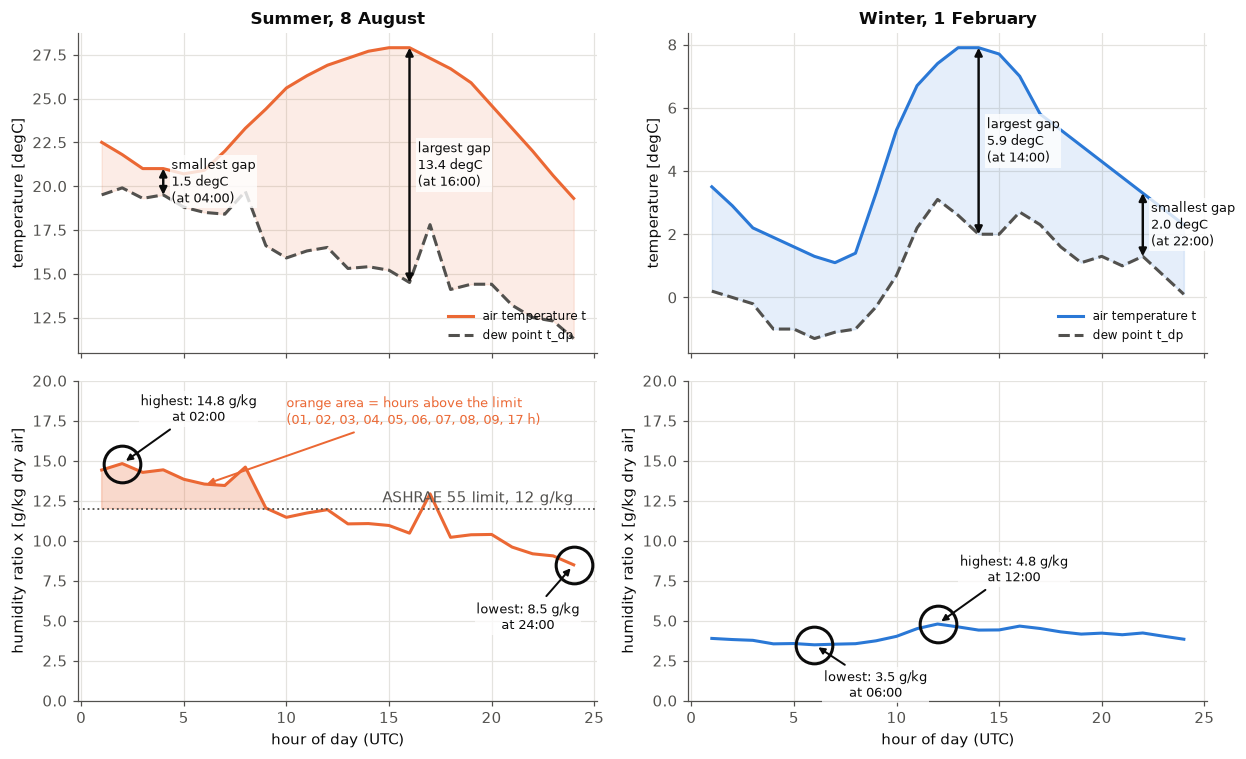

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(11.5, 7), sharex=True)
for col, (name, df, colr) in enumerate((("Summer, 8 August", summer_day, SUMMER), ("Winter, 1 February", winter_day, WINTER))):
    ax = axes[0, col]; hr = df["hour (UTC)"].to_numpy(); t = df["t"].to_numpy(); tdp = df["t_dp"].to_numpy(); xx = df["x [g/kg]"].to_numpy()
    ax.plot(hr, t, color=colr, lw=2, label="air temperature t")
    ax.plot(hr, tdp, color=MUTED, lw=2, ls="--", label="dew point t_dp")
    ax.fill_between(hr, tdp, t, color=colr, alpha=0.12)
    ax.set_title(name); ax.set_ylabel("temperature [degC]"); ax.legend(frameon=False, loc="lower right", fontsize=8)
    for i, word in ((np.argmin(t - tdp), "smallest"), (np.argmax(t - tdp), "largest")):      # double arrow = the gap t - t_dp
        ax.annotate("", (hr[i], tdp[i]), (hr[i], t[i]), arrowprops=dict(arrowstyle="<|-|>", color=INK, lw=1.6, shrinkA=0, shrinkB=0))
        ax.text(hr[i] + 0.4, (t[i] + tdp[i]) / 2, f"{word} gap\n{t[i] - tdp[i]:.1f} degC\n(at {hr[i]:02d}:00)", fontsize=8.5, va="center", bbox=dict(fc="white", ec="none", alpha=0.8, pad=1))
    ax = axes[1, col]
    ax.plot(hr, xx, color=colr, lw=2)
    ax.set_ylabel("humidity ratio x [g/kg dry air]"); ax.set_xlabel("hour of day (UTC)"); ax.set_ylim(0, 20)
    ip = int(np.argmax(xx)); iv = int(np.argmin(xx))
    ring(ax, hr[ip], xx[ip], color=INK); ring(ax, hr[iv], xx[iv], color=INK)
    point(ax, (hr[ip], xx[ip]), f"highest: {xx[ip]:.1f} g/kg\nat {hr[ip]:02d}:00", (50, 28), color=INK)
    point(ax, (hr[iv], xx[iv]), f"lowest: {xx[iv]:.1f} g/kg\nat {hr[iv]:02d}:00", (-30, -42) if col == 0 else (40, -34), color=INK)
xs_ = summer_day["x [g/kg]"].to_numpy(); over = np.where(xs_ > 12)[0] + 1
axes[1, 0].axhline(12, color=MUTED, lw=1.2, ls=":")
axes[1, 0].fill_between(hours, 12, xs_, where=xs_ > 12, color=ORANGE, alpha=0.25)
axes[1, 0].text(24, 12.4, "ASHRAE 55 limit, 12 g/kg", color=MUTED, ha="right")
axes[1, 0].annotate("orange area = hours above the limit\n(" + ", ".join(f"{h:02d}" for h in over) + " h)", (6, 13.5), xytext=(10, 17.3), color=ORANGE, fontsize=8.5,
                    arrowprops=dict(arrowstyle="-|>", color=ORANGE, lw=1.3))
plt.tight_layout(); plt.show()

**Reading it.**
- **Top row:** the vertical double arrows measure the gap between the solid line (air) and the dashed line (dew point), which is how many degrees the air is from fog (100 % relative humidity). In summer the smallest gap is about 1.5 °C at 04:00 (relative humidity 91 %) and the largest 13.4 °C at 16:00 (44 %). In winter the gap stays between 2.0 and 5.9 °C all day.
- **Bottom row:** the rings mark the highest and lowest humidity ratio. In summer the orange area is above 12 g/kg, the limit of the ASHRAE 55 comfort standard (the standard used in Part B and named in the lecture), from 01:00 to 09:00 UTC (13.4 to 14.8 g/kg until 08:00, only just above at 09:00) and again at 17:00. Even in the afternoon, when relative humidity is lowest, the air still holds 10 to 12 g/kg, so it is dry only in relative terms. Winter air never exceeds 4.8 g/kg, which is why heated winter rooms often feel too dry.

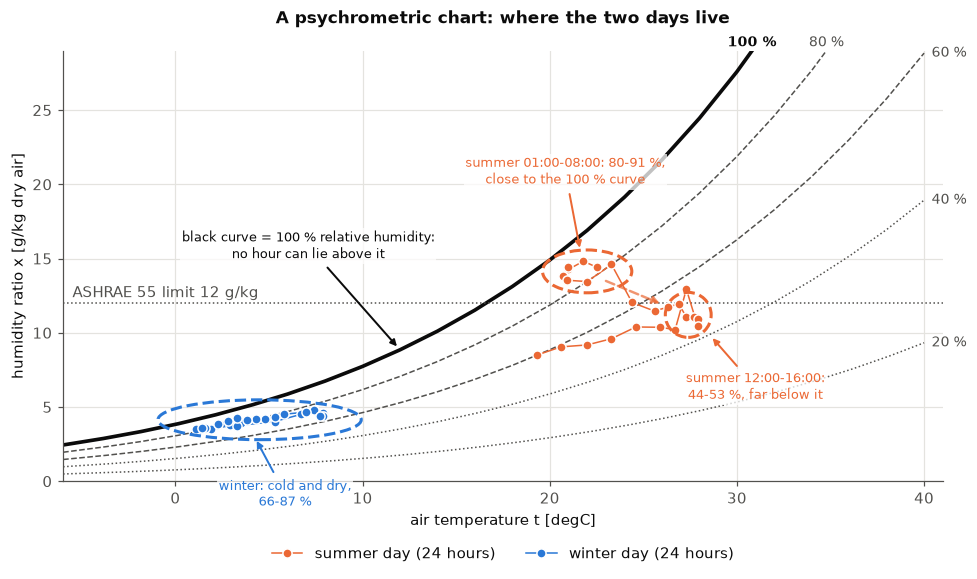

In [14]:
fig, ax = plt.subplots(figsize=(9, 5.4))
tg = np.linspace(-6, 40, 300); TOP = 29
for f, ls, lw, col in ((1.0, "-", 2.4, INK), (0.8, "--", 1, MUTED), (0.6, "--", 1, MUTED), (0.4, ":", 1, MUTED), (0.2, ":", 1, MUTED)):
    y = 1000 * humidity_ratio(f * p_sat(tg)); ax.plot(tg, y, color=col, lw=lw, ls=ls)
    if y[-1] > TOP: ax.text(float(np.interp(TOP, y, tg)), TOP + 0.3, f"{f*100:.0f} %", color=col, ha="center", fontsize=9, fontweight="bold" if f == 1 else "normal")
    else: ax.text(40.4, y[-1], f"{f*100:.0f} %", color=col, va="center", fontsize=9)
ax.axhline(12, color=MUTED, lw=1, ls=":"); ax.text(-5.5, 12.4, "ASHRAE 55 limit 12 g/kg", color=MUTED)
ax.plot(summer_day["t"], summer_day["x [g/kg]"], "o-", color=SUMMER, ms=6, lw=1, mec="white", mew=1, label="summer day (24 hours)")
ax.plot(winter_day["t"], winter_day["x [g/kg]"], "o-", color=WINTER, ms=6, lw=1, mec="white", mew=1, label="winter day (24 hours)")
point(ax, (12, float(1000 * humidity_ratio(p_sat(12)))), "black curve = 100 % relative humidity:\nno hour can lie above it", (-60, 60), color=INK)
n = summer_day[summer_day["hour (UTC)"] <= 8]; a = summer_day[(summer_day["hour (UTC)"] >= 12) & (summer_day["hour (UTC)"] <= 16)]
blob(ax, n["t"], n["x [g/kg]"], SUMMER, 1.0, 0.9); blob(ax, a["t"], a["x [g/kg]"], SUMMER, 1.0, 0.9)
point(ax, (n["t"].mean(), n["x [g/kg]"].max() + 0.6), "summer 01:00-08:00: 80-91 %,\nclose to the 100 % curve", (-10, 45), color=SUMMER)
point(ax, (a["t"].mean() + 1, a["x [g/kg]"].min() - 0.6), "summer 12:00-16:00:\n44-53 %, far below it", (30, -42), color=SUMMER)
ax.annotate("", (a["t"].mean() - 1.5, a["x [g/kg]"].mean() + 0.8), (n["t"].mean() + 1.2, n["x [g/kg]"].mean() - 0.6), arrowprops=dict(arrowstyle="-|>", color=SUMMER, lw=1.6, ls="--", alpha=0.7))
blob(ax, winter_day["t"], winter_day["x [g/kg]"], WINTER, 1.0, 0.8)
point(ax, (winter_day["t"].mean(), winter_day["x [g/kg]"].min() - 0.5), "winter: cold and dry,\n66-87 %", (20, -45), color=WINTER)
ax.set_xlabel("air temperature t [degC]"); ax.set_ylabel("humidity ratio x [g/kg dry air]"); ax.set_ylim(0, TOP); ax.set_xlim(-6, 41)
ax.legend(frameon=False, loc="upper center", ncol=2, bbox_to_anchor=(0.5, -0.12))
ax.set_title("A psychrometric chart: where the two days live", pad=18)
plt.tight_layout(); plt.show()

**Reading it.** This is the classic *psychrometric chart*: temperature across, water content up. Each dot is one hour. The black curve is the **100 % relative humidity** (saturation) curve of A2, drawn here in terms of $x$: no hour can lie above it, because that air would already be fog. The grey curves under it are 80, 60, 40 and 20 %: a dot between two curves has the percentage in between.
- **Summer night** (01:00 to 08:00, dashed oval on the left): 80 to 91 %, just under the black curve, so the air is almost fog.
- **Summer afternoon** (12:00 to 16:00, oval on the right): 44 to 53 %, far below the curve. The dashed arrow shows the day moving from the night oval to the afternoon oval: the air warms and the dots slide away from the 100 % curve.
- **Winter** (blue oval): bottom left, 66 to 87 %, but it holds so little water that it is far below the summer cloud.

Air conditioning moves summer dots **down** (drying) and **left** (cooling) toward the comfort zone.

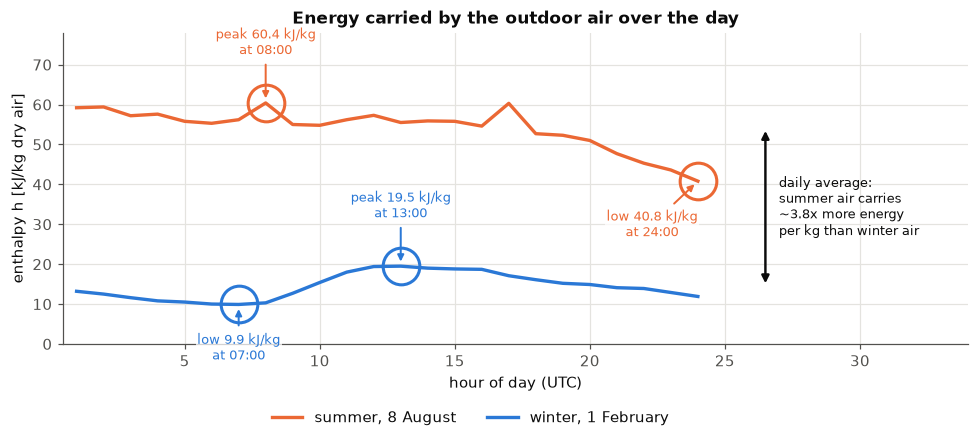

Summer: h from 40.8 to 60.4 kJ/kg;  winter: 9.9 to 19.5 kJ/kg


In [15]:
fig, ax = plt.subplots(figsize=(9, 4.2))
ax.plot(hours, summer_day["h [kJ/kg]"], color=SUMMER, lw=2.2, label="summer, 8 August")
ax.plot(hours, winter_day["h [kJ/kg]"], color=WINTER, lw=2.2, label="winter, 1 February")
hs_, hw_ = summer_day["h [kJ/kg]"].to_numpy(), winter_day["h [kJ/kg]"].to_numpy()
ax.annotate("", (26.5, hw_.mean()), (26.5, hs_.mean()), arrowprops=dict(arrowstyle="<|-|>", color=INK, lw=1.6))
ax.text(27.0, (hs_.mean() + hw_.mean()) / 2, f"daily average:\nsummer air carries\n~{hs_.mean() / hw_.mean():.1f}x more energy\nper kg than winter air", va="center", fontsize=8.5)
for arr, col in ((hs_, SUMMER), (hw_, WINTER)):
    ip, iv = int(arr.argmax()), int(arr.argmin())
    ring(ax, hours[ip], arr[ip], color=col); point(ax, (hours[ip], arr[ip]), f"peak {arr[ip]:.1f} kJ/kg\nat {hours[ip]:02d}:00", (0, 32), color=col)
    ring(ax, hours[iv], arr[iv], color=col); point(ax, (hours[iv], arr[iv]), f"low {arr[iv]:.1f} kJ/kg\nat {hours[iv]:02d}:00", (-30 if iv > 20 else 0, -36), color=col)
ax.set_xlabel("hour of day (UTC)"); ax.set_ylabel("enthalpy h [kJ/kg dry air]"); ax.set_xlim(0.5, 34); ax.set_ylim(0, 78)
ax.legend(frameon=False, loc="upper center", ncol=2, bbox_to_anchor=(0.45, -0.17))
ax.set_title("Energy carried by the outdoor air over the day")
plt.tight_layout(); plt.show()
print(f"Summer: h from {summer_day['h [kJ/kg]'].min()} to {summer_day['h [kJ/kg]'].max()} kJ/kg;  winter: {winter_day['h [kJ/kg]'].min()} to {winter_day['h [kJ/kg]'].max()} kJ/kg")

**Reading it.** The two-headed arrow on the right compares the daily averages: summer air carries roughly three times as much energy per kg as winter air (41 to 60 kJ/kg against 10 to 20). The rings mark each curve's highest and lowest hour. The summer peak is at 08:00, not in the hot afternoon, because that is when the air is still very humid (14.6 g/kg) and already warm (A7 explains this link). An air-handling unit's workload follows these curves: the higher $h$, the more energy it needs to bring the air to indoor conditions.

## A7. Reading the curves: what moves when something else moves

The charts above show a handful of quantities, and they are **computed from each other** with the formulas of A3: only the air temperature $t$ and the relative humidity $\varphi$ are measured, and everything else follows. This section uses the 24 hourly values of both days to show **which curves rise and fall together, which are mirror images, and why**, with the pattern marked on each figure.

**How to read a correlation.** The correlation $r$ between two curves is a number from −1 to +1. Hour by hour it asks: when curve A is above its own average, is curve B above its average too?

- $r$ close to **+1**: they rise and fall together (left plot, orange arrow slopes up);
- $r$ near **0**: no relation, the dots form a cloud (middle plot);
- $r$ close to **−1**: mirror images, when one rises the other falls (right plot, arrow slopes down).

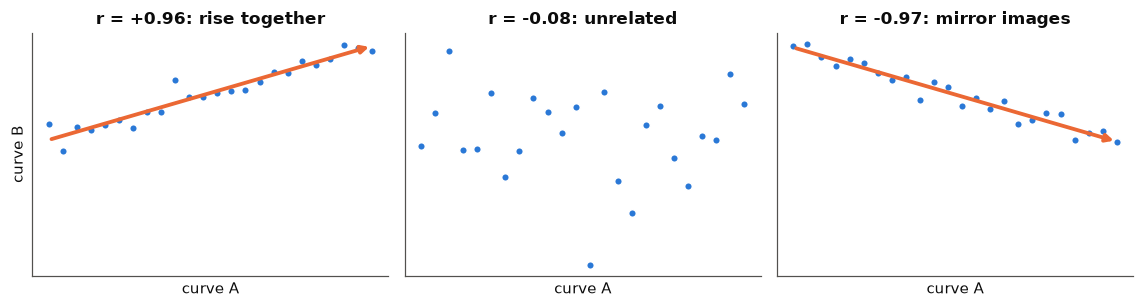

,Summer,Winter
t vs RH,-0.75,-0.89
t vs x,-0.23,0.93
tdp vs x,1.00,1.00
gap vs RH,-1.00,-1.00
x vs h,0.84,0.96
t vs h,0.33,0.99


In [16]:
def daily(t, phi):
    pv = phi / 100 * p_sat(t); x = 1000 * humidity_ratio(pv); tdp = t_sat(pv)
    return dict(t=t, RH=phi, x=x, tdp=tdp, gap=t - tdp, h=enthalpy(t, x / 1000))
DAYS = {"Summer": (daily(t_s, f_s), SUMMER), "Winter": (daily(t_w, f_w), WINTER)}
corr = lambda d, a, b: np.corrcoef(d[a], d[b])[0, 1]

# what a correlation looks like: three toy pairs of curves
rng = np.random.default_rng(3); u = np.linspace(0, 1, 24)
toy = [("rise together", 2 * u + 0.15 * rng.normal(size=24)), ("unrelated", rng.normal(size=24)), ("mirror images", 2 - 2 * u + 0.15 * rng.normal(size=24))]
fig, axs = plt.subplots(1, 3, figsize=(10.5, 2.9), sharex=True, sharey=True)
for ax, (name, y) in zip(axs, toy):
    r = np.corrcoef(u, y)[0, 1]; k = np.polyfit(u, y, 1)
    ax.plot(u, y, "o", color=BLUE, ms=5, mec="white")
    if abs(r) > 0.5:
        ax.annotate("", (1, np.polyval(k, 1)), (0, np.polyval(k, 0)), arrowprops=dict(arrowstyle="-|>", color=ORANGE, lw=2.5))
    ax.set_title(f"r = {r:+.2f}: {name}"); ax.set_xlabel("curve A"); ax.set_xticks([]); ax.set_yticks([])
axs[0].set_ylabel("curve B")
plt.tight_layout(); plt.show()

pairs = [("t", "RH"), ("t", "x"), ("tdp", "x"), ("gap", "RH"), ("x", "h"), ("t", "h")]
display(pd.DataFrame({n: {f"{a} vs {b}": round(corr(d, a, b), 2) for a, b in pairs} for n, (d, _) in DAYS.items()}))

The six correlations measured on the two days are in the table above (rows = pairs of curves). The rest of the section goes through them one by one.

**Map of the links.** Every arrow means "is computed from". The map shows in advance which curves must be related:
1. **Water amount.** $\varphi$ and $t$ give $p_v$, and then both $x$ and $t_{dp}$ come from $p_v$ alone. So $x$ and $t_{dp}$ are *the same information* in g/kg and in °C: their curves must have the same shape (section 3).
2. **Relative humidity.** $\varphi=p_v/p_{sat}(t)$ uses $t$ again, through the growing $p_{sat}(t)$. If $t$ goes up and the water stays the same, $\varphi$ must go down (section 2). The gap $t-t_{dp}$ measures the same thing in degrees (section 4).
3. **Energy.** $h$ takes $t$ as its sensible part and $x$ as its latent part, so it follows whichever of the two changes more over the day (section 5).

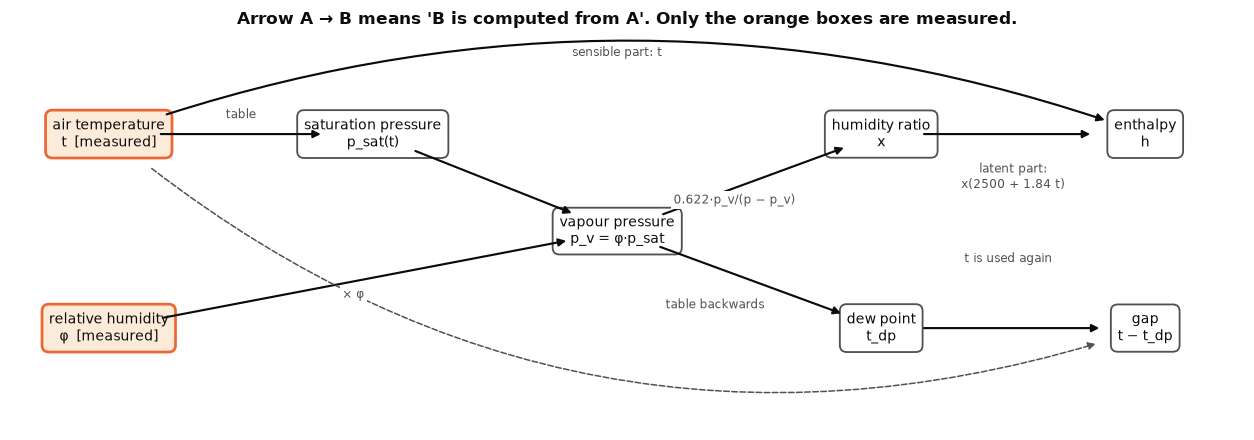

In [17]:
fig, ax = plt.subplots(figsize=(11.5, 4.1)); ax.set_xlim(0, 12.6); ax.set_ylim(-0.4, 4.7); ax.axis("off")
pos = {"t": (1.0, 3.4), "phi": (1.0, 0.9), "psat": (3.7, 3.4), "pv": (6.2, 2.15), "x": (8.9, 3.4), "tdp": (8.9, 0.9), "h": (11.6, 3.4), "gap": (11.6, 0.9)}
txt = {"t": "air temperature\nt  [measured]", "phi": "relative humidity\nφ  [measured]", "psat": "saturation pressure\np_sat(t)", "pv": "vapour pressure\np_v = φ·p_sat", "x": "humidity ratio\nx", "tdp": "dew point\nt_dp", "h": "enthalpy\nh", "gap": "gap\nt − t_dp"}
for k, (px, py) in pos.items():
    given = k in ("t", "phi")
    ax.text(px, py, txt[k], ha="center", va="center", fontsize=9, zorder=3,
            bbox=dict(boxstyle="round,pad=0.5", fc="#fdebd9" if given else "white", ec=ORANGE if given else MUTED, lw=1.8 if given else 1.2))
def arrow(a, b, label="", lab_xy=None, rad=0.0, sh=(34, 34)):
    ax.annotate("", pos[b], pos[a], arrowprops=dict(arrowstyle="-|>", color=INK, lw=1.4, shrinkA=sh[0], shrinkB=sh[1], connectionstyle=f"arc3,rad={rad}"))
    if label: ax.text(*lab_xy, label, fontsize=8, ha="center", va="center", color=MUTED, bbox=dict(fc="white", ec="none", pad=1.5), zorder=4)
arrow("t", "psat", "table", (2.35, 3.65)); arrow("psat", "pv", "", sh=(30, 32)); arrow("phi", "pv", "× φ", (3.5, 1.33), sh=(36, 34))
arrow("pv", "x", "0.622·p_v/(p − p_v)", (7.4, 2.55), sh=(32, 26)); arrow("pv", "tdp", "table backwards", (7.2, 1.2), sh=(30, 28))
arrow("t", "h", "sensible part: t", (6.2, 4.45), rad=-0.18, sh=(40, 28)); arrow("x", "h", "latent part:\nx(2500 + 1.84 t)", (10.25, 2.85), sh=(28, 36))
arrow("tdp", "gap", "", sh=(28, 30))
ax.annotate("", pos["gap"], pos["t"], arrowprops=dict(arrowstyle="-|>", color=MUTED, lw=1, ls="--", shrinkA=36, shrinkB=34, connectionstyle="arc3,rad=0.28"))
ax.text(10.2, 1.75, "t is used again", fontsize=8, color=MUTED, ha="center")
ax.set_title("Arrow A → B means 'B is computed from A'. Only the orange boxes are measured.")
plt.tight_layout(); plt.show()

### 2. Temperature and relative humidity: mirror images

If the air warms and gains no water, $p_v$ stays the same but $p_{sat}(t)$ grows (A2), so $\varphi=p_v/p_{sat}$ falls. Over a day the temperature rises from the morning minimum to the afternoon peak, so relative humidity should fall in the same hours.

In the figure the coloured line is $t$ (left axis) and the dashed black line is $\varphi$ (right axis). The wide translucent arrows cover the morning-to-afternoon stretch: **$t$ climbs while $\varphi$ drops**. The rings mark the extreme hours and the dotted vertical line the hour of the lowest $\varphi$.
- **Summer** ($r=-0.75$): $t$ climbs from 20.7 °C (05:00) to 27.9 °C (15:00) while $\varphi$ drops from 89 % to 46 %. $\varphi$ is lowest (44 %) at 16:00, one hour after the temperature peak, and highest (91 %) at 04:00, when $t$ is only 21 °C. The mirror is not perfect because the water in the air also changes: at 17:00 $\varphi$ jumps from 44 % to 56 % while $t$ falls only 0.6 °C.
- **Winter** ($r=-0.89$): $t$ climbs from 1.1 °C (07:00) to 7.9 °C (13:00) while $\varphi$ drops from 85 % to 69 %. The swing is smaller (66 to 87 % all day) because the winter air also gains water as it warms (section 3), which partly refills the bigger $p_{sat}$.

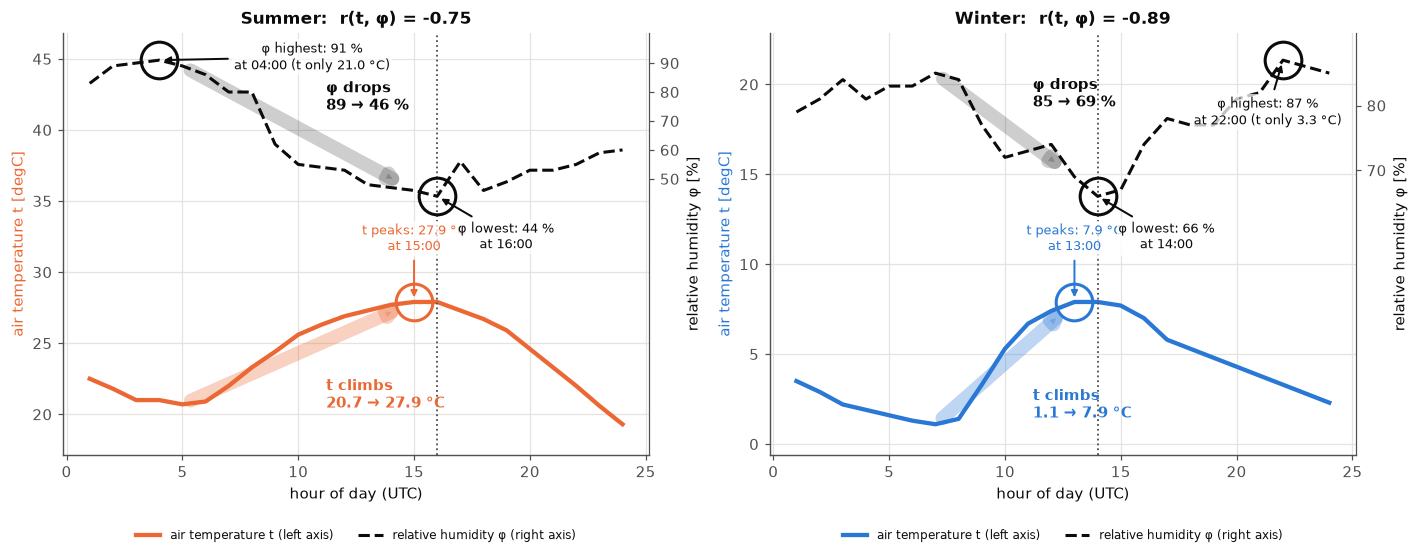

In [18]:
fig, axs = plt.subplots(1, 2, figsize=(13, 5.2), sharex=True)
for ax, (n, (d, col)) in zip(axs, DAYS.items()):
    t, rh = d["t"], d["RH"]; Rt, Rr = np.ptp(t), np.ptp(rh)
    ax.plot(hours, t, color=col, lw=2.8, label="air temperature t (left axis)")                  # t lives in the lower band, phi in the upper band
    ax.set_xlabel("hour of day (UTC)"); ax.set_ylabel("air temperature t [degC]", color=col)
    ax.set_ylim(t.min() - 0.25 * Rt, t.max() + 2.2 * Rt)
    ax2 = ax.twinx(); ax2.spines["right"].set_visible(True); ax2.grid(False)
    ax2.plot(hours, rh, color=INK, lw=2, ls="--", label="relative humidity φ (right axis)")
    ax2.set_ylabel("relative humidity φ [%]"); ax2.set_ylim(rh.min() - 1.9 * Rr, rh.max() + 0.2 * Rr)
    ax2.set_yticks(np.arange(np.ceil(rh.min() / 10) * 10, rh.max() + 1, 10))
    it, il, ir = int(t.argmax()), int(rh.argmin()), int(rh.argmax())
    i0 = int(t[:it + 1].argmin())                                      # coolest hour before the peak
    ax.annotate("", (hours[it], t[it]), (hours[i0], t[i0]), arrowprops=dict(arrowstyle="-|>", color=col, lw=9, alpha=0.30, shrinkA=6, shrinkB=6))
    ax2.annotate("", (hours[it], rh[it]), (hours[i0], rh[i0]), arrowprops=dict(arrowstyle="-|>", color=INK, lw=9, alpha=0.20, shrinkA=6, shrinkB=6))
    ax.text((hours[i0] + hours[it]) / 2 + 1.2, (t[i0] + t[it]) / 2 - 0.2 * Rt, f"t climbs\n{t[i0]:.1f} → {t[it]:.1f} °C", color=col, fontweight="bold", ha="left", va="top", fontsize=9.5)
    ax2.text((hours[i0] + hours[it]) / 2 + 1.2, (rh[i0] + rh[it]) / 2 + 0.1 * Rr, f"φ drops\n{rh[i0]:.0f} → {rh[it]:.0f} %", color=INK, fontweight="bold", ha="left", va="bottom", fontsize=9.5)
    ax.axvline(hours[il], color=MUTED, ls=":", lw=1.2)
    ring(ax, hours[it], t[it], color=col); ring(ax2, hours[il], rh[il], color=INK); ring(ax2, hours[ir], rh[ir], color=INK)
    point(ax, (hours[it], t[it]), f"t peaks: {t[it]} °C\nat {hours[it]:02d}:00", (0, 34), color=col)
    point(ax2, (hours[il], rh[il]), f"φ lowest: {rh[il]} %\nat {hours[il]:02d}:00", (45, -34), color=INK)
    point(ax2, (hours[ir], rh[ir]), f"φ highest: {rh[ir]} %\nat {hours[ir]:02d}:00 (t only {t[ir]} °C)", (100, -6) if n == "Summer" else (-10, -42), color=INK)
    h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
    ax.legend(h1 + h2, l1 + l2, frameon=False, loc="upper center", ncol=2, fontsize=8, bbox_to_anchor=(0.5, -0.15))
    ax.set_title(f"{n}:  r(t, φ) = {corr(d, 't', 'RH'):+.2f}")
plt.tight_layout(); plt.show()

### 3. Dew point and humidity ratio: the same curve

$t_{dp}$ is $p_v$ read backwards in the saturation table, and $x=0.622\,p_v/(p-p_v)$. Both are functions of $p_v$ alone, so they are one quantity written in °C and in g/kg.

In the first two panels the dashed line ($x$, right axis) lies on top of the solid line ($t_{dp}$, left axis); the two axes are scaled so the shapes can overlay. The dotted vertical lines and rings mark the hours of the highest and the lowest value: **both curves peak and bottom out in the same hour**, $r=1.00$.
- **Summer:** both highest at 02:00 ($t_{dp}$ 19.9 °C, $x$ 14.8 g/kg), both lowest at 24:00 (11.3 °C, 8.5 g/kg).
- **Winter:** both highest at 12:00 (3.1 °C, 4.8 g/kg), both lowest at 06:00 (−1.3 °C, 3.5 g/kg).

The right panel plots $x$ against $t_{dp}$. All 48 hours fall on **one curve, the saturation curve of A2** (the 100 % line) written as $x_{sat}$ at the temperature $t_{dp}$. This is the definition of the dew point: air with humidity ratio $x$ is 100 % full exactly at the temperature where $x$ meets the saturation curve. The summer ring sits high on the curve (humid, high dew point), the winter ring low on it (dry, low dew point).

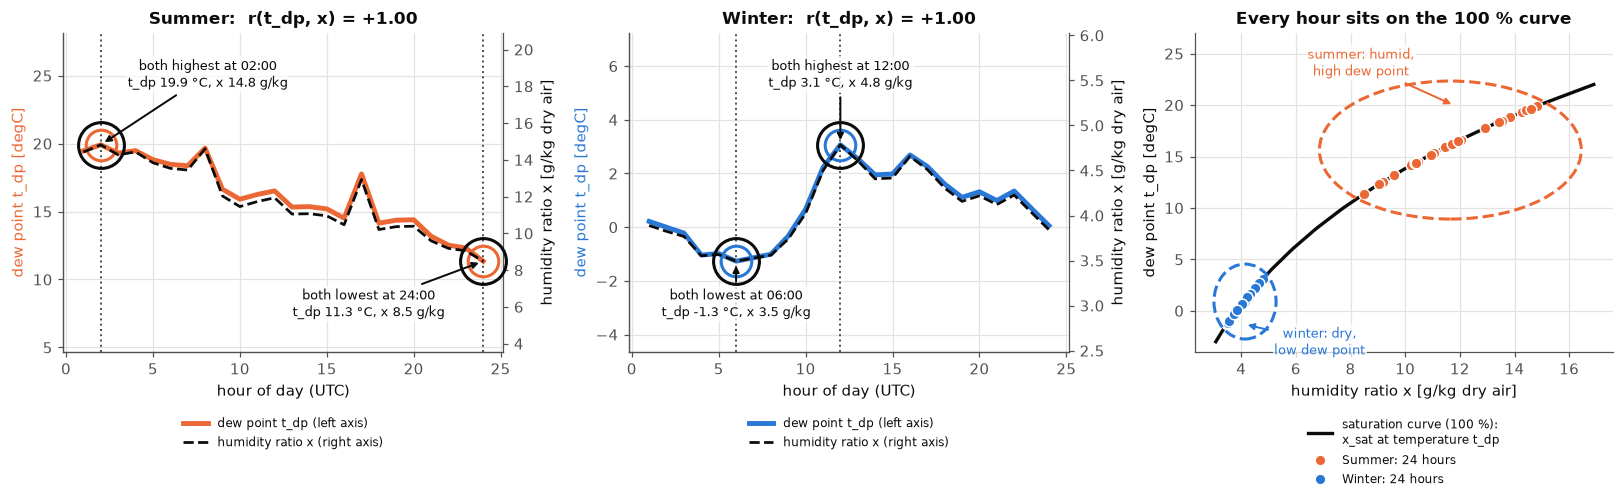

In [19]:
fig, axs = plt.subplots(1, 3, figsize=(15, 4.8), gridspec_kw=dict(width_ratios=[1, 1, 0.95]))
for ax, (n, (d, col)) in zip(axs[:2], DAYS.items()):
    tdp, xx = d["tdp"], d["x"]
    s = np.ptp(xx) / np.ptp(tdp); m = 0.3 * np.ptp(tdp)                 # scale the two axes so the curves can overlay
    ax.plot(hours, tdp, color=col, lw=3.2, label="dew point t_dp (left axis)")
    ax.set_ylim(tdp.min() - 2.6 * m, tdp.max() + 3.2 * m); ax.set_xlabel("hour of day (UTC)"); ax.set_ylabel("dew point t_dp [degC]", color=col)
    ax2 = ax.twinx(); ax2.spines["right"].set_visible(True); ax2.grid(False)
    ax2.plot(hours, xx, color=INK, lw=1.8, ls="--", label="humidity ratio x (right axis)")
    ax2.set_ylim(xx.min() - 2.6 * m * s, xx.max() + 3.2 * m * s); ax2.set_ylabel("humidity ratio x [g/kg dry air]")
    for i, word in ((int(xx.argmax()), "highest"), (int(xx.argmin()), "lowest")):
        ax.axvline(hours[i], color=MUTED, ls=":", lw=1.3); ring(ax, hours[i], tdp[i], color=col, size=20); ring(ax2, hours[i], xx[i], color=INK, size=30)
        off = {"highest": (70 if hours[i] < 6 else 0, 38), "lowest": (-75 if hours[i] > 18 else 0, -36)}[word]
        point(ax2, (hours[i], xx[i]), f"both {word} at {hours[i]:02d}:00\nt_dp {tdp[i]:.1f} °C, x {xx[i]:.1f} g/kg", off, color=INK)
    h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
    ax.legend(h1 + h2, l1 + l2, frameon=False, loc="upper center", ncol=1, fontsize=8, bbox_to_anchor=(0.5, -0.17))
    ax.set_title(f"{n}:  r(t_dp, x) = {corr(d, 'tdp', 'x'):+.2f}")
ax = axs[2]
tc = np.linspace(-3, 22, 100); ax.plot(1000 * humidity_ratio(p_sat(tc)), tc, color=INK, lw=2.2, label="saturation curve (100 %):\nx_sat at temperature t_dp")
for n, (d, col) in DAYS.items():
    ax.plot(d["x"], d["tdp"], "o", color=col, ms=7, mec="white", label=f"{n}: 24 hours")
    blob(ax, d["x"], d["tdp"], col, 0.4, 1.0)
point(ax, (DAYS["Summer"][0]["x"].mean(), DAYS["Summer"][0]["tdp"].max()), "summer: humid,\nhigh dew point", (-62, 20), color=SUMMER)
point(ax, (DAYS["Winter"][0]["x"].mean(), DAYS["Winter"][0]["tdp"].min()), "winter: dry,\nlow dew point", (50, -20), color=WINTER)
ax.set_ylim(-4, 27); ax.set_xlabel("humidity ratio x [g/kg dry air]"); ax.set_ylabel("dew point t_dp [degC]"); ax.legend(frameon=False, loc="upper center", fontsize=8, bbox_to_anchor=(0.5, -0.17))
ax.set_title("Every hour sits on the 100 % curve")
plt.tight_layout(); plt.show()

### 4. The gap $t-t_{dp}$ and relative humidity

The gap is how many degrees the air must cool before it reaches 100 % relative humidity (A4). So the smaller the gap, the fuller the air: at **gap = 0 the relative humidity is exactly 100 %** (the star on the figure). The points fall along a line sloping down from the star, $r=-1.00$ on both days: the larger the gap, the drier the air.

The dashed ovals show where the hours sit:
- **Summer night** (01:00 to 08:00): gap 1.5 to 3.6 °C and $\varphi$ 80 to 91 %, close to the star, so the air is almost fog.
- **Summer afternoon** (12:00 to 16:00): gap 10.4 to 13.4 °C and $\varphi$ 44 to 53 %, the dry end of the line.
- **Winter** (all hours): gap 2.0 to 5.9 °C and $\varphi$ 66 to 87 %, never far from fog, even though the absolute water content is small.

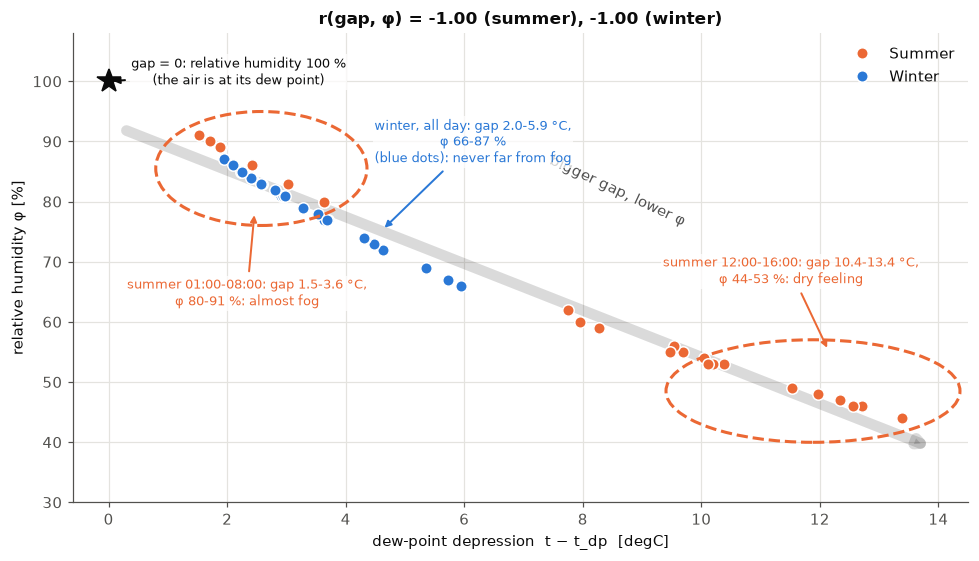

In [20]:
fig, ax = plt.subplots(figsize=(9, 5.2))
allg = np.concatenate([d["gap"] for d, _ in DAYS.values()]); allr = np.concatenate([d["RH"] for d, _ in DAYS.values()]); fit = np.polyfit(allg, allr, 1)
for n, (d, col) in DAYS.items():
    ax.plot(d["gap"], d["RH"], "o", color=col, ms=7.5, mec="white", label=n, zorder=5)
ax.annotate("", (allg.max() + 0.5, np.polyval(fit, allg.max() + 0.5)), (0.3, np.polyval(fit, 0.3)), arrowprops=dict(arrowstyle="-|>", color=INK, lw=7, alpha=0.15, shrinkA=0, shrinkB=0))
ax.plot(0, 100, "*", color=INK, ms=16, zorder=7); point(ax, (0, 100), "gap = 0: relative humidity 100 %\n(the air is at its dew point)", (85, -2), color=INK)
S, W = DAYS["Summer"][0], DAYS["Winter"][0]
night, aft = slice(0, 8), slice(11, 16)
blob(ax, S["gap"][night], S["RH"][night], SUMMER, 0.5, 3); blob(ax, S["gap"][aft], S["RH"][aft], SUMMER, 0.6, 4)
point(ax, (S["gap"][night].mean(), S["RH"][night].min() - 1.5), f"summer 01:00-08:00: gap {S['gap'][night].min():.1f}-{S['gap'][night].max():.1f} °C,\nφ {S['RH'][night].min()}-{S['RH'][night].max()} %: almost fog", (-5, -62), color=SUMMER)
point(ax, (S["gap"][aft].mean(), S["RH"][aft].max() + 2), f"summer 12:00-16:00: gap {S['gap'][aft].min():.1f}-{S['gap'][aft].max():.1f} °C,\nφ {S['RH'][aft].min()}-{S['RH'][aft].max()} %: dry feeling", (-25, 45), color=SUMMER)
point(ax, (4.6, np.polyval(fit, 4.6)), f"winter, all day: gap {W['gap'].min():.1f}-{W['gap'].max():.1f} °C,\nφ {W['RH'].min()}-{W['RH'].max()} %\n(blue dots): never far from fog", (60, 45), color=WINTER)
ax.text(7.4, 76, "bigger gap, lower φ", color=INK, rotation=-25, alpha=0.7, fontsize=10)
ax.set_xlabel("dew-point depression  t − t_dp  [degC]"); ax.set_ylabel("relative humidity φ [%]"); ax.set_xlim(-0.6, 14.5); ax.set_ylim(30, 108); ax.legend(frameon=False, loc="upper right")
ax.set_title(f"r(gap, φ) = {corr(S, 'gap', 'RH'):+.2f} (summer), {corr(W, 'gap', 'RH'):+.2f} (winter)")
plt.tight_layout(); plt.show()

### 5. Enthalpy: does it follow the temperature or the water?

$h=t+x\,(2500+1.84\,t)$ is a sensible part ($t$) plus a latent part (proportional to $x$), so $h$ follows whichever varies more over the day. Each panel plots $h$ against one of them; the wide stripe is the trend line and the label says whether it is a tight line or a loose cloud.
- **Winter** ($r(t,h)=0.99$, $r(x,h)=0.96$): $t$ and $x$ rise together ($r(t,x)=0.93$), so $h$ follows both and both panels are tight lines. The sensible part swings by 6.8 kJ/kg (1.1 to 7.9 °C) and the latent part by only 3.3 kJ/kg (8.7 to 12.0), so temperature leads.
- **Summer** ($r(t,h)=0.33$, $r(x,h)=0.84$): here $t$ and $x$ are almost unrelated ($r=-0.23$): the humid hours are the cool night hours. The latent part swings by 16.1 kJ/kg (21.5 to 37.6) and the sensible part by 8.6 kJ/kg (19.3 to 27.9 °C), so the water leads. The temperature panel is a loose cloud, the water panel a much tighter line.
- **The rings in the summer panels** mark two hours. At 08:00 the temperature is only 23.3 °C, yet $h$ is the day's highest (60.4 kJ/kg) because $x$ is 14.6 g/kg. At 24:00 it is the coolest and driest hour, with the lowest $h$ (40.8 kJ/kg).

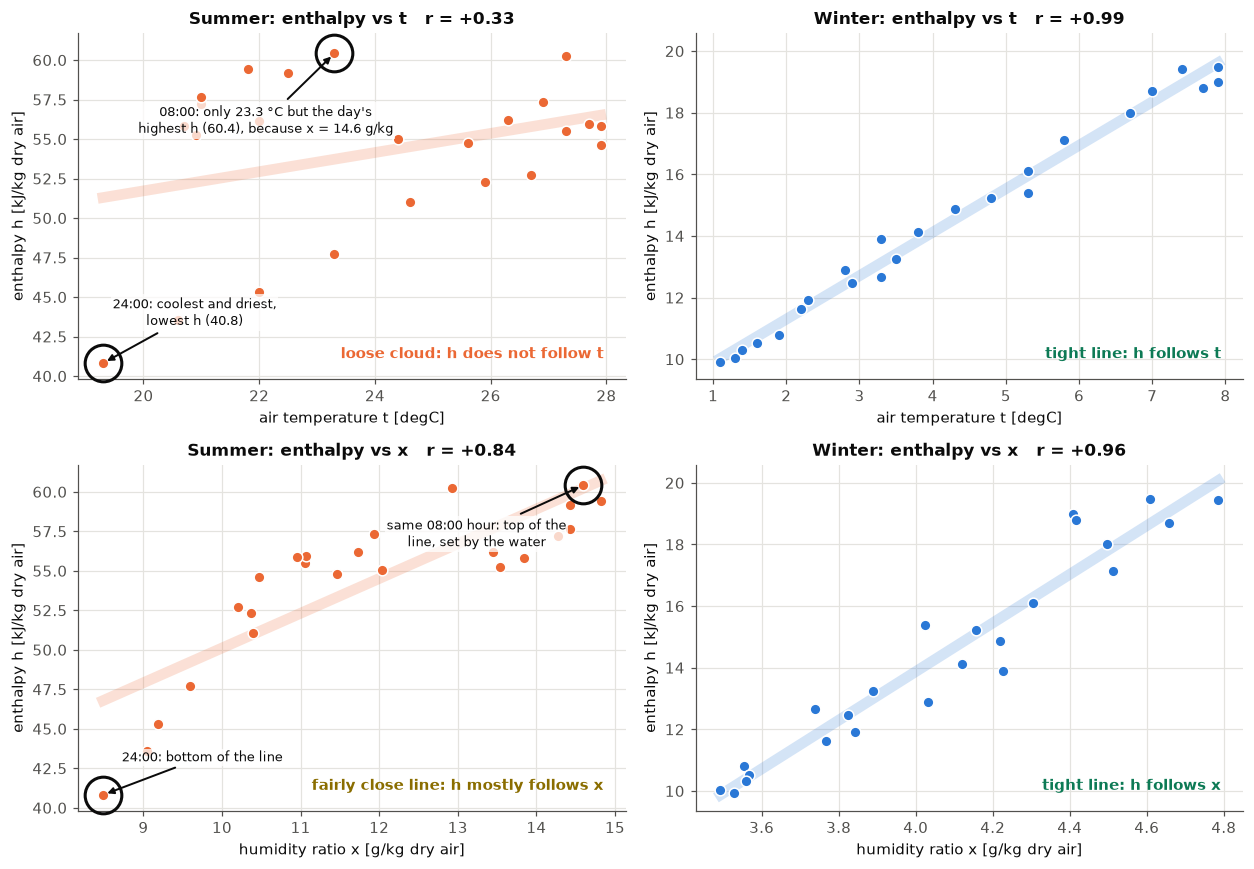

In [21]:
fig, axs = plt.subplots(2, 2, figsize=(11.5, 8), sharey="col")
for j, (n, (d, col)) in enumerate(DAYS.items()):
    for i, (key, xl) in enumerate((("t", "air temperature t [degC]"), ("x", "humidity ratio x [g/kg dry air]"))):
        ax = axs[i, j]; k = np.polyfit(d[key], d["h"], 1); xs_ = np.array([d[key].min(), d[key].max()])
        ax.plot(xs_, np.polyval(k, xs_), color=col, lw=7, alpha=0.2)
        ax.plot(d[key], d["h"], "o", color=col, ms=7, mec="white")
        r = corr(d, key, "h"); verdict, vcol = (f"tight line: h follows {key}", "#0d7a55") if abs(r) > 0.9 else ((f"fairly close line: h mostly follows {key}", "#8a6d00") if abs(r) > 0.6 else (f"loose cloud: h does not follow {key}", ORANGE))
        ax.set_title(f"{n}: enthalpy vs {key}   r = {r:+.2f}", color=INK)
        ax.text(0.96, 0.05, verdict, transform=ax.transAxes, ha="right", va="bottom", color=vcol, fontweight="bold", fontsize=9.5)
        ax.set_xlabel(xl); ax.set_ylabel("enthalpy h [kJ/kg dry air]")
S = DAYS["Summer"][0]; ih, il = int(S["h"].argmax()), int(S["h"].argmin())
for i, key in enumerate(("t", "x")):
    ring(axs[i, 0], S[key][ih], S["h"][ih], color=INK); ring(axs[i, 0], S[key][il], S["h"][il], color=INK)
point(axs[0, 0], (S["t"][ih], S["h"][ih]), f"{hours[ih]:02d}:00: only {S['t'][ih]} °C but the day's\nhighest h ({S['h'][ih]:.1f}), because x = {S['x'][ih]:.1f} g/kg", (-45, -52), color=INK)
point(axs[0, 0], (S["t"][il], S["h"][il]), f"{hours[il]:02d}:00: coolest and driest,\nlowest h ({S['h'][il]:.1f})", (60, 25), color=INK)
point(axs[1, 0], (S["x"][ih], S["h"][ih]), f"same {hours[ih]:02d}:00 hour: top of the\nline, set by the water", (-70, -40), color=INK)
point(axs[1, 0], (S["x"][il], S["h"][il]), f"{hours[il]:02d}:00: bottom of the line", (65, 22), color=INK)
plt.tight_layout(); plt.show()

# Part B: Sheet 2, the comfort challenge (PMV, PPD, $t_o$)

Sheet 1 described the air. Now we look at the **person in the air**.

### What do PMV and PPD stand for, and where do they come from?

**PMV = Predicted Mean Vote.** In the 1960s the Danish professor P. O. Fanger put volunteers in climate chambers, changed the air temperature, humidity, air speed, clothing and activity, and asked them to **vote** on how they felt on the **7-point thermal sensation scale** (the ASHRAE scale): −3 cold, −2 cool, −1 slightly cool, 0 neutral, +1 slightly warm, +2 warm, +3 hot. He published the method in his book *Thermal Comfort* (1970).
- **Vote**: one person's answer on that 7-point scale.
- **Mean**: the average vote of a large group of people in the same room.
- **Predicted**: nobody is asked. The number is *calculated* from the six inputs ($t_a$, $t_{mr}$, $v$, relative humidity, clothing, activity) with the heat balance of the body: heat produced minus heat lost is the thermal load $L$, and $PMV=TS\cdot L$. If heat piles up ($L>0$) people vote warm, if the body loses heat faster than it makes it ($L<0$) they vote cool.

**PPD = Predicted Percentage of Dissatisfied.** People differ, so even in a room that is right for the average person some are unhappy. PPD is the percentage of a large group who would be *dissatisfied*, which means they would vote **warm or hot (+2, +3) or cool or cold (−2, −3)**. Fanger fitted this curve to the votes: $PPD = 100-95\,e^{-0.03353\,PMV^4-0.2179\,PMV^2}$. It is smallest (5 %) at $PMV=0$ and grows quickly on both sides.

**ISO 7730** (ISO = International Organization for Standardization) is the international standard that fixes how to calculate PMV and PPD, including the iteration of Step 3. **ASHRAE 55** (ASHRAE = American Society of Heating, Refrigerating and Air-Conditioning Engineers; standard 55, *Thermal Environmental Conditions for Human Occupancy*) uses the same model to define comfort zones.

## B0. The big picture: six factors, six drains

The lecture says thermal comfort is a **heat balance** between body and environment, controlled by **four environmental** and **two personal** factors:

| Environmental | Personal |
|---|---|
| air temperature $t_a$, mean radiant temperature $t_{mr}$, air speed $v$, humidity RH | metabolic rate $M_{met}$, clothing $I_{clo}$ |

The body makes heat $M$. Six paths remove it ($RL_1$ to $RL_6$). What remains is the load $L$, and $PMV = TS\cdot L$.

Which factor drives which drain? The table below changes each factor by one typical step and shows how many W/m² each drain moves by (orange = drain grows, blue = shrinks). The hot summer day is the base case.

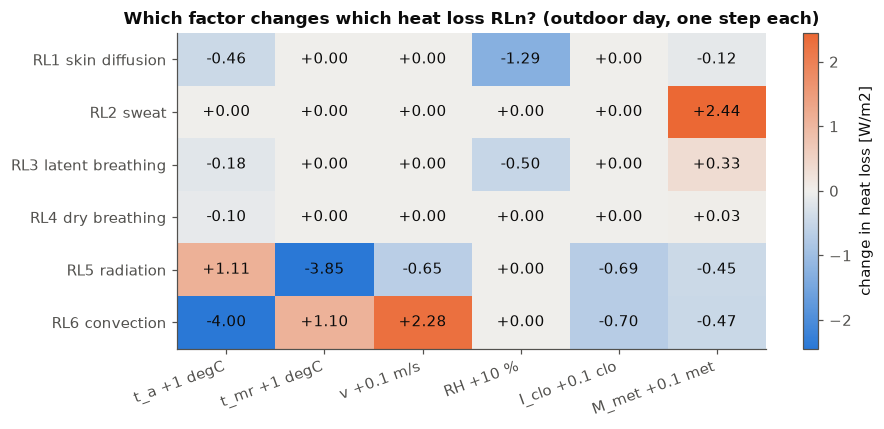

In [22]:
BASE = dict(t_a=30, t_mr=30.5, v=0.15, rh=60, i_clo=0.5, m_met=1.2)
STEP = {"t_a +1 degC": ("t_a", 1), "t_mr +1 degC": ("t_mr", 1), "v +0.1 m/s": ("v", 0.1),
        "RH +10 %": ("rh", 10), "I_clo +0.1 clo": ("i_clo", 0.1), "M_met +0.1 met": ("m_met", 0.1)}
keys = ["RL1", "RL2", "RL3", "RL4", "RL5", "RL6"]
*_, d0 = calculate_pmv_ppd(**BASE, details=True)
grid = np.array([[calculate_pmv_ppd(**{**BASE, p: BASE[p] + s}, details=True)[-1][k] - d0[k] for p, s in STEP.values()] for k in keys])
labels = ["RL1 skin diffusion", "RL2 sweat", "RL3 latent breathing", "RL4 dry breathing", "RL5 radiation", "RL6 convection"]
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm
cmap = LinearSegmentedColormap.from_list("div", [BLUE, "#f0efec", ORANGE])
fig, ax = plt.subplots(figsize=(8.5, 4))
im = ax.imshow(grid, cmap=cmap, norm=TwoSlopeNorm(0, vmin=-grid.max(), vmax=grid.max()), aspect="auto")
ax.set_xticks(range(6)); ax.set_xticklabels(list(STEP), rotation=20, ha="right"); ax.set_yticks(range(6)); ax.set_yticklabels(labels); ax.grid(False)
for i in range(6):
    for j in range(6):
        ax.text(j, i, f"{grid[i, j]:+.2f}", ha="center", va="center", color=INK)
fig.colorbar(im, label="change in heat loss [W/m2]"); ax.set_title("Which factor changes which heat loss RLn? (outdoor day, one step each)")
plt.tight_layout(); plt.show()

**Reading it.** Each column is a factor, each row a drain.
- **Humidity** acts only on the two vapour drains ($RL_1$, $RL_3$): it is the $p_v$ of sheet 1. More humid air means *less* vapour loss (blue).
- **Metabolic rate** mostly adds **sweat** ($RL_2$, +2.4 W/m² per 0.1 met). The other drains change slightly, because a busier body has a cooler skin and clothing.
- **Air speed** acts on convection ($RL_6$, +2.3 W/m² per 0.1 m/s). Radiation drops a little because the clothes get cooler.
- **$t_a$ and $t_{mr}$ push in opposite directions on the two big drains:** warmer air shrinks convection loss (−4.0), warmer walls shrink radiation loss (−3.9), while the other drain rises slightly. In both cases total heat loss falls and PMV rises.
- **Clothing** reduces both radiation and convection (about −0.7 each per 0.1 clo): it is the insulation.

## B1. Metabolic rate in depth (lecture slides 16 to 20)

A resting adult produces about **100 W** of heat. Spread over the skin (about 1.7 m² on average; 1.8 m² for a European man, 1.6 m² for a woman) this is about 58 W/m², which is what defines **1 met**. The lab uses the exact value 58.15 W/m². The lecture also gives two helpful formulas.

**Skin temperature** falls as activity rises (more sweat cools the skin): $t_{sk} = 35.7 - 0.0275\,(M - W)$, with $W$ the mechanical work done (zero for desk work). The lab's clothing-balance equation uses $35.7 - 0.028\,M$, the same idea rounded.

**Measuring M from breathing** (Nishi 1981): $M = 21\,(0.23\,RQ+0.77)\,\dfrac{\dot V_{O_2}}{A_D}$, where $RQ$ is the *respiratory quotient* (CO₂ out / O₂ in; it tells which fuel the body burns: about 0.7 for fats, 1.0 for carbohydrates, about 0.83 for a mixed diet), $\dot V_{O_2}$ is oxygen consumption (mL/s) and $A_D$ is skin area (m²).

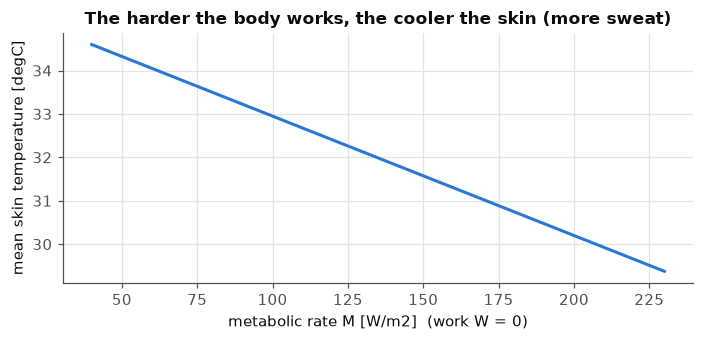

In [23]:
M = np.linspace(40, 230, 100)
fig, ax = plt.subplots(figsize=(6.5, 3.2))
ax.plot(M, 35.7 - 0.0275 * M, color=BLUE, lw=2)
ax.set_xlabel("metabolic rate M [W/m2]  (work W = 0)"); ax.set_ylabel("mean skin temperature [degC]")
ax.set_title("The harder the body works, the cooler the skin (more sweat)")
plt.tight_layout(); plt.show()

**Reading it.** The skin temperature drops about 1 °C between resting and 1.5 met, which is why $t_{cl}$ depends on $M$ in the iteration. Above about 3 met the activity is poorly defined and the values can be off by ±50 %, so PMV is a less reliable number there.

## B2. Clothing in depth

- **clo** is the unit of clothing insulation. **1 clo = 0.155 m²·K/W**: the thermal resistance of a typical winter business suit. 0.5 clo is light summer clothing.
- Clothes also **enlarge the surface** that exchanges heat. The *clothing area factor* $f_{cl}$ = clothed surface / nude surface:

$$f_{cl}=\begin{cases}1+1.29\,I_{cl} & I_{cl}<0.078\\[2pt] 1.05+0.645\,I_{cl} & I_{cl}\ge0.078\end{cases}$$

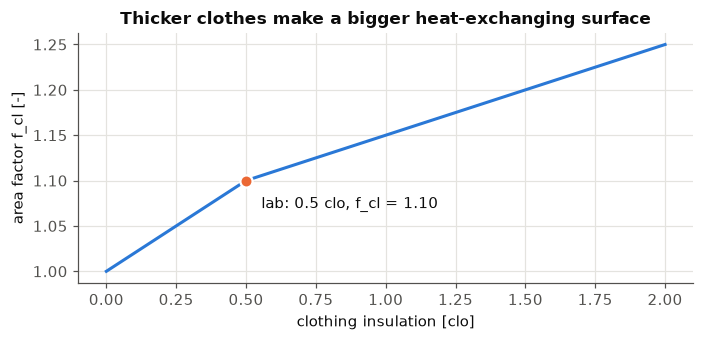

In [24]:
clo = np.linspace(0, 2, 200); icl = 0.155 * clo
fcl = np.where(icl < 0.078, 1 + 1.29 * icl, 1.05 + 0.645 * icl)
fig, ax = plt.subplots(figsize=(6.5, 3.2))
ax.plot(clo, fcl, color=BLUE, lw=2)
ax.plot(0.5, 1 + 1.29 * 0.155 * 0.5, "o", color=ORANGE, ms=8, mec="white", mew=1.5); ax.annotate("lab: 0.5 clo, f_cl = 1.10", (0.5, 1.1), xytext=(10, -18), textcoords="offset points")
ax.set_xlabel("clothing insulation [clo]"); ax.set_ylabel("area factor f_cl [-]"); ax.set_title("Thicker clothes make a bigger heat-exchanging surface")
plt.tight_layout(); plt.show()

**Reading it.** At 0.5 clo the insulation is just under the 0.078 threshold, so the **first** branch applies (it differs only slightly from the second). The area factor is about 1.10: a lightly dressed body exchanges heat over a surface 10 % larger than bare skin.

## B3. Mean radiant temperature and operative temperature, properly

**Mean radiant temperature** $t_{mr}$ is the average temperature of everything the body "sees", weighted by how much of the body faces each surface. The lecture gives weights for a **seated** person (up/down, right/left, front/back):

$$t_{mr}=\frac{0.18(t_{up}+t_{down})+0.22(t_{right}+t_{left})+0.30(t_{front}+t_{back})}{2(0.18+0.22+0.30)}$$

(standing: 0.08, 0.23, 0.35). In the lab we are simply **given** $t_{mr}$ = 30.5 °C.

**Operative temperature.** The lecture's physical definition is a weighted average with the two heat-transfer coefficients as weights:

$$t_o=\frac{h_c\,t_a+h_r\,t_{mr}}{h_c+h_r},\qquad h_r = 4\,\varepsilon\,\sigma\,\frac{A_r}{A_D}\Big(273.2+\frac{t_{cl}+t_{mr}}{2}\Big)^3$$

with $h_c$ convective and $h_r$ radiative coefficient [W/(m²·K)], $\varepsilon$ emissivity (assumed 0.95 here), $\sigma = 5.67\cdot10^{-8}$ W/(m²K⁴), $A_r/A_D$ = 0.70 sitting or 0.73 standing.

The **sheet simplifies this to fixed weights** (0.5/0.5, 0.6/0.4, 0.7/0.3 depending on air speed). Let us check that the simplification is reasonable.

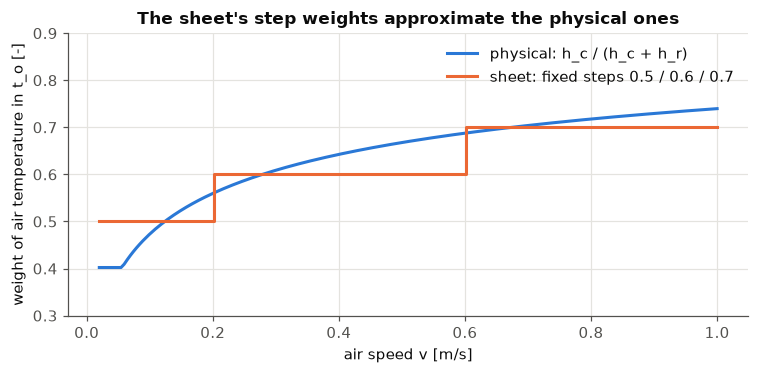

In [25]:
eps, sigma, ar_ad = 0.95, 5.67e-8, 0.70                         # emissivity assumed; sitting person
t_a_, t_mr_, t_cl_ = 30, 30.5, 32.1                               # lab day; t_cl from the iteration
h_r = 4 * eps * sigma * ar_ad * (273.2 + (t_cl_ + t_mr_) / 2) ** 3
v_axis = np.linspace(0.02, 1.0, 200)
h_c = np.maximum(12.1 * np.sqrt(v_axis), 2.38 * abs(t_cl_ - t_a_) ** 0.25)
w_air = h_c / (h_c + h_r)                                         # weight of air temperature in t_o
w_sheet = np.where(v_axis < 0.2, 0.5, np.where(v_axis < 0.6, 0.6, 0.7))
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(v_axis, w_air, color=BLUE, lw=2, label="physical: h_c / (h_c + h_r)")
ax.step(v_axis, w_sheet, color=ORANGE, lw=2, where="post", label="sheet: fixed steps 0.5 / 0.6 / 0.7")
ax.set_xlabel("air speed v [m/s]"); ax.set_ylabel("weight of air temperature in t_o [-]"); ax.set_ylim(0.3, 0.9); ax.legend(frameon=False)
ax.set_title("The sheet's step weights approximate the physical ones")
plt.tight_layout(); plt.show()

**Reading it.** The physical curve rises with air speed (more convection, so air counts more), just like the sheet's steps. At the lab's 0.15 m/s the physical weight is about 0.52 against the sheet's 0.50, so the two operative temperatures (30.24 and 30.25 °C) are practically identical. The sheet's version needs no iteration and no emissivity, which makes it easy to code and good enough for control.

## B4. The heart of the code: the $t_{cl}$ iteration (what the sheet calls Step 3)

Why iterate? $t_{cl}$ sets how much heat leaves by radiation ($\propto T_{cl}^4$) and convection ($h_c$ depends on $t_{cl}-t_a$), and those losses in turn set $t_{cl}$. The sheet's recipe is *guess, recompute, repeat until the change is below $\epsilon=0.0015$*.

**Why our numbers match the sheet exactly.** The reference result (PMV 1.767, 8 iterations) only appears with this ISO 7730 form: kelvin = °C + 273.15, the balance constant 308.7 (=35.7 + 273), unknown $x=T_{cl}/100$, old/new values averaged each round, and the stopping test applied to $x$ (so 0.0015 means 0.15 K). A looser or different choice gives PMV 1.71 to 1.76, which is close but does not match the sheet.

In [26]:
pmv, ppd, t_o, n, d = calculate_pmv_ppd(**BASE, details=True)
hist = pd.DataFrame({"iteration": range(len(d["history"])), "t_cl guess [degC]": np.round(d["history"], 4)})
hist["change vs previous"] = hist["t_cl guess [degC]"].diff().round(4)
display(hist.set_index("iteration").T)
print(f"-> t_cl = {d['t_cl']:.2f} degC after {n} iterations;  h_c = {d['h_c']:.2f} W/m2K;  f_cl = {d['f_cl']:.2f}")

iteration,0,1,2,3,4,5,6,7,8
t_cl guess [degC],32.6196,-38.2183,19.1346,27.9415,30.7089,31.6252,31.9464,32.0615,32.1030
change vs previous,NaN,-70.8379,57.3529,8.8069,2.7674,0.9163,0.3212,0.1151,0.0415


-> t_cl = 32.10 degC after 8 iterations;  h_c = 4.69 W/m2K;  f_cl = 1.10


## B5. Reading PMV and PPD like a standard (lecture slides 28 to 30)

- **PMV scale:** +3 hot, +2 warm, +1 slightly warm, 0 neutral, −1 slightly cool, −2 cool, −3 cold.
- **Even at PMV = 0, at least 5 % of people are dissatisfied.**
- **Validity:** the model assumes sweating is small, so PMV is only applicable for $-2 < PMV < +2$. It is **not applicable for hot environments**.
- **Romanian regulation I5 (the national normative that defines the comfort categories, as named in the lecture)** sorts rooms into four categories:

| Category | Who it suits | PPD | PMV range |
|---|---|---|---|
| **I** high | children, elderly, sick | < 6 % | −0.2 … 0.2 |
| **II** medium | normal for new / renovated buildings | < 10 % | −0.5 … 0.5 |
| **III** moderate | existing buildings | < 15 % | −0.7 … 0.7 |
| **IV** low | short periods only | > 15 % | beyond ±0.7 |

The lab's target, −0.5 < PMV < 0.5, is category **II**.

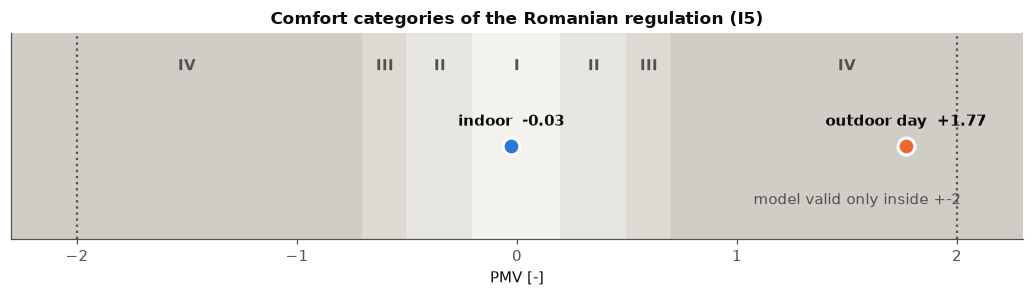

In [27]:
pm_out = calculate_pmv_ppd(**BASE)[0]
pm_in = calculate_pmv_ppd(t_a=24.5, t_mr=25, v=0.15, rh=60, i_clo=0.5, m_met=1.2)[0]
fig, ax = plt.subplots(figsize=(9.5, 2.8))
cats = [("IV", -2.3, -0.7, "#cfcdc6"), ("III", -0.7, -0.5, "#dcdad3"), ("II", -0.5, -0.2, "#e8e6e0"), ("I", -0.2, 0.2, "#f3f2ee"),
        ("II", 0.2, 0.5, "#e8e6e0"), ("III", 0.5, 0.7, "#dcdad3"), ("IV", 0.7, 2.3, "#cfcdc6")]
for name, lo, hi, colr in cats:
    ax.axvspan(lo, hi, color=colr, zorder=0); ax.text((lo + hi) / 2, 0.82, name, ha="center", fontweight="bold", color=MUTED)
ax.axvline(-2, color=MUTED, ls=":"); ax.axvline(2, color=MUTED, ls=":"); ax.text(2.02, 0.15, "model valid only inside +-2", color=MUTED, ha="right", va="bottom")
for xv, lab, colr in ((pm_in, "indoor", BLUE), (pm_out, "outdoor day", ORANGE)):
    ax.plot(xv, 0.45, "o", color=colr, ms=11, mec="white", mew=2); ax.text(xv, 0.55, f"{lab}  {xv:+.2f}", ha="center", fontweight="bold")
ax.set_xlim(-2.3, 2.3); ax.set_ylim(0, 1); ax.set_yticks([]); ax.grid(False); ax.set_xlabel("PMV [-]")
ax.set_title("Comfort categories of the Romanian regulation (I5)")
plt.tight_layout(); plt.show()

**Reading it.** Our indoor room (PMV −0.03) sits in the centre, **category I**, the strictest one (|PMV| < 0.2, PPD 5.0 % < 6 %). The outdoor day (+1.77) is in category IV, and its value is just inside the ±2 validity limit, so the number can be trusted but is close to the edge.

## B6. Applying the comfort model to the whole summer day

The challenge refers to *"the considered day in the previous simulation"*. Here we run the hourly summer data of sheet 1 through the comfort program, assuming (as the sheet does for its single case) $t_{mr}=t_a+0.5$ °C, $v=0.15$ m/s, 0.5 clo, 1.2 met. **This is an extension, not something the sheet asks for**: it shows how the outdoor air would feel to a person dressed for summer.

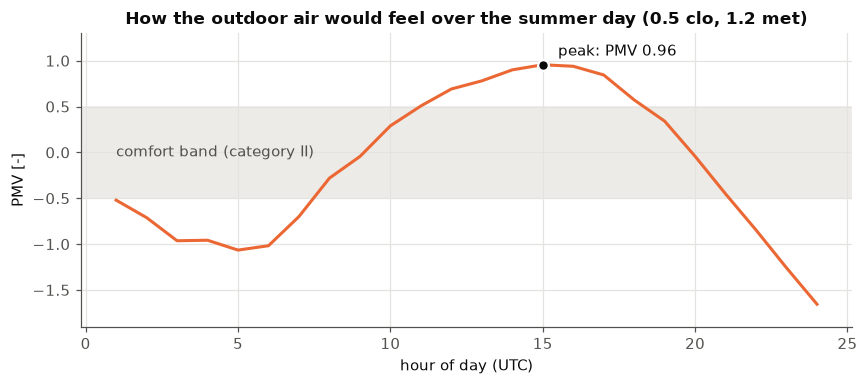

PMV from -1.66 (hour 24) to 0.96 (hour 15)


In [28]:
pmv_day = np.array([calculate_pmv_ppd(t, t + 0.5, rh=f)[0] for t, f in zip(t_s, f_s)])
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.axhspan(-0.5, 0.5, color=BAND, zorder=0); ax.text(1, 0.0, "comfort band (category II)", color=MUTED, va="center")
ax.plot(hours, pmv_day, color=SUMMER, lw=2)
ax.plot(15, pmv_day[14], "o", color=INK, ms=7, mec="white", mew=1.5)
ax.annotate(f"peak: PMV {pmv_day[14]:.2f}", (15, pmv_day[14]), xytext=(10, 6), textcoords="offset points", ha="left")
ax.set_ylim(-1.9, 1.3)
ax.set_xlabel("hour of day (UTC)"); ax.set_ylabel("PMV [-]"); ax.set_title("How the outdoor air would feel over the summer day (0.5 clo, 1.2 met)")
plt.tight_layout(); plt.show()
print(f"PMV from {pmv_day.min():.2f} (hour {hours[pmv_day.argmin()]}) to {pmv_day.max():.2f} (hour {hours[pmv_day.argmax()]})")

**Reading it.** The air is **cool** at night and in the early morning (PMV down to −1.66 at the last hour, 19.3 °C), comfortable around 08:00 to 11:00 and again 18:00 to 21:00 UTC, and **warm** from noon to evening (peak +0.96 at 15:00 UTC, 27.9 °C and 46 %). The sheet's example state (30 °C, 60 %) is hotter and more humid than any hour of this particular day, which is why its PMV (+1.77) is higher than this day's peak.

## B7. Finding the indoor conditions (the second half of the challenge)

The sheet fixes RH, $v$, clothing and activity, and lets us change $t_a$, $t_{mr}$ (and RH). **Summer rule: $t_{mr}=t_a+0.5$.** We search for the $t_a$ range where $-0.5<PMV<0.5$, and compare with the ASHRAE 55 operative-temperature ranges from the lecture: **23 to 26 °C in summer (0.5 clo), 20 to 24 °C in winter (1.0 clo)**.

Summer clothes (0.5 clo, 1.2 met): -0.5 < PMV < 0.5 for t_a from 23.01 to 26.14 degC  (t_o 23.26 to 26.39)
Winter clothes (1.0 clo, 1.2 met): -0.5 < PMV < 0.5 for t_a from 19.16 to 23.51 degC  (t_o 19.41 to 23.76)


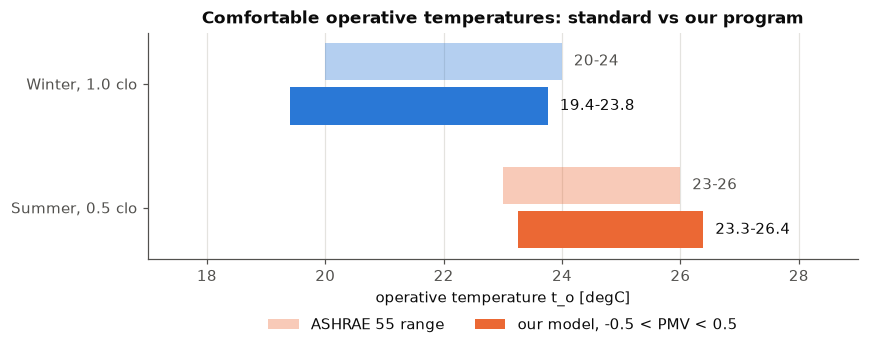

In [29]:
f = lambda ta, **kw: calculate_pmv_ppd(ta, ta + 0.5, **kw)[0]
lo_s, hi_s = brentq(lambda t: f(t) + 0.5, 15, 30), brentq(lambda t: f(t) - 0.5, 15, 30)
print(f"Summer clothes (0.5 clo, 1.2 met): -0.5 < PMV < 0.5 for t_a from {lo_s:.2f} to {hi_s:.2f} degC  (t_o {lo_s + 0.25:.2f} to {hi_s + 0.25:.2f})")
lo_w, hi_w = brentq(lambda t: f(t, i_clo=1.0) + 0.5, 10, 30), brentq(lambda t: f(t, i_clo=1.0) - 0.5, 10, 30)
print(f"Winter clothes (1.0 clo, 1.2 met): -0.5 < PMV < 0.5 for t_a from {lo_w:.2f} to {hi_w:.2f} degC  (t_o {lo_w + 0.25:.2f} to {hi_w + 0.25:.2f})")

fig, ax = plt.subplots(figsize=(8, 3.4))
for y, (name, lo, hi, a, b, colr) in enumerate((("Summer, 0.5 clo", lo_s + .25, hi_s + .25, 23, 26, SUMMER), ("Winter, 1.0 clo", lo_w + .25, hi_w + .25, 20, 24, WINTER))):
    ax.barh(y + 0.18, b - a, left=a, height=0.3, color=colr, alpha=0.35, label="ASHRAE 55 range" if y == 0 else None)
    ax.barh(y - 0.18, hi - lo, left=lo, height=0.3, color=colr, label="our model, -0.5 < PMV < 0.5" if y == 0 else None)
    ax.text(b + 0.2, y + 0.18, f"{a}-{b}", va="center", color=MUTED); ax.text(hi + 0.2, y - 0.18, f"{lo:.1f}-{hi:.1f}", va="center")
ax.set_yticks([0, 1]); ax.set_yticklabels(["Summer, 0.5 clo", "Winter, 1.0 clo"]); ax.set_xlim(17, 29); ax.grid(axis="y", visible=False)
ax.set_xlabel("operative temperature t_o [degC]"); ax.set_title("Comfortable operative temperatures: standard vs our program")
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=2)
plt.tight_layout(); plt.show()

**Reading it.** Light bars = the ASHRAE 55 ranges from the lecture. Solid bars = what our PMV program says (PMV between ±0.5). They overlap well, which is a good sign the code is right: the program reproduces the standard's comfort zone. Winter people wear twice the clothing, so the comfortable air temperature is lower.

## B8. Why the comfortable temperature depends on activity

Lecture slide 24: for activity above 70 W/m² the comfortable operative temperature **drops**, because the body makes more heat. Our program shows the same effect (summer clothes, $t_{mr}=t_a+0.5$):

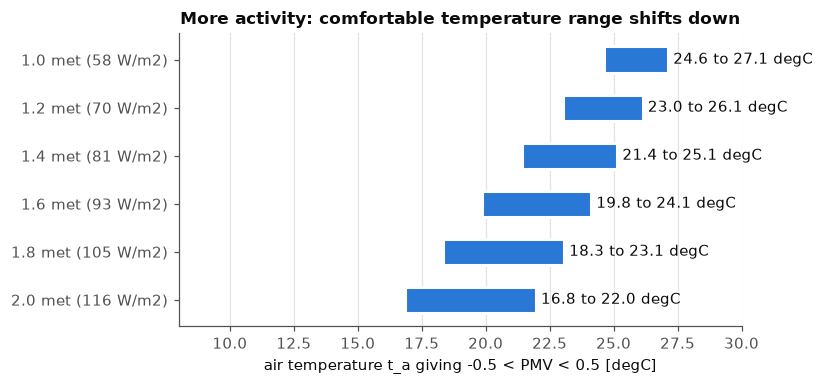

In [30]:
mets = [1.0, 1.2, 1.4, 1.6, 1.8, 2.0]
rng = [(brentq(lambda t: f(t, m_met=m) + 0.5, 5, 30), brentq(lambda t: f(t, m_met=m) - 0.5, 5, 30)) for m in mets]
fig, ax = plt.subplots(figsize=(7.5, 3.6))
for i, (m, (a, b)) in enumerate(zip(mets, rng)):
    ax.barh(i, b - a, left=a, height=0.55, color=BLUE, edgecolor="white", linewidth=2)
    ax.text(b + 0.2, i, f"{a:.1f} to {b:.1f} degC", va="center")
ax.set_yticks(range(len(mets))); ax.set_yticklabels([f"{m} met ({m * 58.15:.0f} W/m2)" for m in mets]); ax.invert_yaxis()
ax.set_xlim(8, 30); ax.grid(axis="y", visible=False); ax.set_xlabel("air temperature t_a giving -0.5 < PMV < 0.5 [degC]")
ax.set_title("More activity: comfortable temperature range shifts down")
plt.tight_layout(); plt.show()

**Reading it.** Every extra 0.2 met lowers the comfortable air temperature by about 1.3 °C (the range is 24.6 to 27.1 °C at 1.0 met and 16.8 to 22.0 °C at 2.0 met). So a room that is perfect for a seated student feels hot to someone doing a lab practical on their feet.

## B9. Summary: what to hand in and how the pieces fit

| Question | Sheet | Answer |
|---|---|---|
| Mass / density of air in 6×4×3 m room at 25 °C | 1 | 84.14 kg, 1.17 kg/m³ (slide: 1.16) |
| Summer 30 °C, 60 %: $p_{sat}$, $p_v$, $x$, $t_{dp}$, $h$ | 1 | 4247 Pa, 2548 Pa, 16.26 g/kg, 21.4 °C, 71.6 kJ/kg |
| Winter 0 °C, 85 %: same | 1 | 611.2 Pa, 519.5 Pa, 3.25 g/kg, −2.2 °C, 8.1 kJ/kg |
| Outdoor comfort (30 / 30.5 °C, 60 %) | 2 | PMV 1.767, PPD 65.3 %, $t_o$ 30.25 °C, 8 iterations |
| Indoor comfort (24.5 / 25 °C, 60 %) | 2 | PMV −0.027, PPD 5.0 %, $t_o$ 24.75 °C, 8 iterations (category I) |

In [31]:
print(sheet1.T.to_string()); print()
for name, cs in (("Outdoor", BASE), ("Indoor", dict(t_a=24.5, t_mr=25, v=0.15, rh=60, i_clo=0.5, m_met=1.2))):
    pmv, ppd, t_o, n = calculate_pmv_ppd(**cs)
    print(f"{name}:  PMV= {pmv:.3f}   PPD= {ppd:.1f} %   t_o= {t_o:.2f} degC   n iterations= {n}")

            t [degC]  phi [%]  p_sat(t) [Pa]  p_v = phi*p_sat [Pa]  x [g/kg]  t_dp [degC]  h [kJ/kg]
Summer day      30.0     60.0         4247.0                2548.2     16.26        21.37      71.56
Winter day       0.0     85.0          611.2                 519.5      3.25        -2.23       8.12

Outdoor:  PMV= 1.767   PPD= 65.3 %   t_o= 30.25 degC   n iterations= 8
Indoor:  PMV= -0.027   PPD= 5.0 %   t_o= 24.75 degC   n iterations= 8
